# 05 — Decision rules, value of an action and business case (G1)

G1 connects the stage-F risk queue to an operational policy and a simulated business case.
The 2016 policy-selection scores are rebuilt weekly with models fitted strictly before each
decision. Estimator selection uses only matured 2015 labels; the final F model tuned on 2016
is used only for the 2017 evaluation. Full weekly batches determine tiers and call capacity;
only outcomes known by 2016-12-31 contribute to the policy-selection objective.

Snapshot feature values and the population proxy retain F's retrospective limitations.
Guest uplift/backfire and finance are assumptions, not measured causal effects. Policy
transfer from the historical estimator to final F must be confirmed in the randomised pilot.
All current results are generated below and exported to `artifacts/business_case/`.


In [1]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
from scipy.stats import norm

ROOT = Path.cwd()
while not (ROOT / 'config' / 'assumptions.yaml').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Run this notebook inside the repository.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import f_modeling as fm
import g1_decision as gd

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

A = yaml.safe_load((ROOT / 'config' / 'assumptions.yaml').read_text(encoding='utf-8'))
G, FIN, OPS = A['g1'], A['finance'], A['operations']
MOD = ROOT / 'artifacts' / 'modeling'
OUT = ROOT / 'artifacts' / 'business_case'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
MANIFEST_F = json.loads((MOD / 'manifest.json').read_text(encoding='utf-8'))
print('Stage-F run used:', MANIFEST_F['run_id'])

# chart style: grey first, one blue accent (dataviz reference palette); text never in series colour
INK, INK2, GRID, MUTED, ACCENT = '#0b0b0b', '#52514e', '#e4e2dd', '#b9b7b0', '#2a78d6'
GOOD, BAD = '#3f8f4f', '#c4513f'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'savefig.dpi': 200,
                     'savefig.bbox': 'tight', 'figure.facecolor': 'white'})
def save(fig, name):
    fig.savefig(FIG / name)
    plt.show()

Stage-F run used: f-v3.1-2026-10-19_20261020-101915


## 1. Data and the value of one prevented cancellation

For a booking that **was** cancelled, preventing the cancellation is worth the simulated **net loss proxy** of notebook 03 §2.6 (one contribution basis, nothing counted twice):

`avoidable loss = contribution of the stay − deposit retained + handling cost − resale contribution`

where contribution = gross × (1 − commission) − room cost × nights, and resale contribution = resale revenue × (1 − resale commission) − room cost × resold nights (simulated by notebook 02). `g1.resale_scale` stress-tests the resale part.

For a booking that **would have stayed** but cancels because of a reminder (backfire), the loss is the same contribution, plus handling, minus the resale the hotel could expect with that notice (`operations.resale_probability` by notice × demand, at `resale_price_factor` of the booking's own ADR).

In [2]:
P = pd.read_csv(ROOT / 'data/processed/bookings_prepared.csv',
                parse_dates=['booking_date', 'arrival_date', 'reservation_status_date'])
pop = pd.read_csv(ROOT / 'data/processed/modeling_dataset.csv', usecols=['booking_id', 'population'])
P = P.merge(pop, on='booking_id', how='left')

# demand at arrival: occupancy of (arrival date, reserved room type) in the simulated inventory table
ops = pd.read_csv(ROOT / 'data/synthetic/ops_inventory_daily.csv', parse_dates=['stay_date'])
occ = ops.set_index(['stay_date', 'room_type'])['occupancy_rate']
P['arrival_occupancy'] = occ.reindex(pd.MultiIndex.from_arrays([P['arrival_date'], P['reserved_room_type']])).to_numpy()
P['demand'] = np.where(P['arrival_occupancy'].fillna(0) >= OPS['high_demand_occupancy_threshold']['value'], 'high_demand', 'normal')

dep_share = FIN['deposit_retained_share']['value']
resale_comm = FIN['resale_commission_rate']['value']
staff_hour = FIN['staff_cost_per_hour']['value']
RP = OPS['resale_probability']['value']

def avoidable_loss(f, resale_scale=G['resale_scale']['value']):
    """Notebook 03 §2.6 net loss proxy (simulated) for a cancelled booking."""
    deposit = f['deposit_type'].astype(str).map(dep_share).fillna(0.0) * f['gross_value']
    resale = (f['syn_rebooking_revenue'].fillna(0.0) * (1 - resale_comm)
              - f['syn_room_cost_per_night'] * f['syn_rebooked_room_nights'].fillna(0.0))
    return (f['syn_net_booking_value'] - deposit + f['syn_cancellation_handling_cost'].fillna(0.0)
            - resale_scale * resale)

def notice_bucket(days):
    days = np.asarray(days, dtype=float)
    return np.select([days >= 30, days >= 8], ['notice_30_plus', 'notice_8_29'], 'notice_0_7')

def resale_prob(bucket, demand):
    return np.array([RP[b][d] for b, d in zip(bucket, demand)], dtype=float)

P['resale_unit_value'] = (P['gross_value'] * OPS['resale_price_factor']['value'] * (1 - resale_comm)
                          - P['syn_room_cost_per_night'] * P['total_nights']).clip(lower=0)
P['avoidable_loss'] = np.where(P['is_canceled'].eq(1), avoidable_loss(P), np.nan)
c = P[P['is_canceled'].eq(1) & P['population'].eq('individual')]
print(f"Individual cancelled bookings: {len(c):,}; mean avoidable loss EUR {c['avoidable_loss'].mean():,.0f} "
      f"(median {c['avoidable_loss'].median():,.0f}; gross value mean {c['gross_value'].mean():,.0f})")

Individual cancelled bookings: 16,062; mean avoidable loss EUR 156 (median 119; gross value mean 424)


## 2. Cost of one action

| Action | Rule | Cost driver | Base cost |
|---|---|---|---|
| Phone call | I3 | `call_minutes_per_attempt` × `call_attempts_per_booking` × `staff_cost_per_hour` | computed below |
| Personalised reminder | I2 | (e-mail + SMS) per message, 1–2 messages, only while the booking is still active | computed below |
| Standard confirmation + 7-day reminder | I1 | already current practice in every scenario | 0 (not incremental) |
| Buffer count | I5 | none (revenue-manager report) | 0 |

In [3]:
def unit_costs(prm):
    call = prm['call_attempts'] * prm['call_minutes'] / 60 * staff_hour
    msg = prm['sms_cost'] + prm['email_cost']
    return call, msg

BASE = {'uplift_call': G['uplift']['value']['phone_call'], 'uplift_rem': G['uplift']['value']['reminder'],
        'backfire_call': G['backfire']['value']['phone_call'], 'backfire_rem': G['backfire']['value']['reminder'],
        'call_minutes': G['call_minutes_per_attempt']['value'], 'call_attempts': G['call_attempts_per_booking']['value'],
        'sms_cost': G['sms_cost_per_message']['value'], 'email_cost': G['email_cost_per_message']['value'],
        'resale_scale': G['resale_scale']['value']}
CALL_COST, MSG_COST = unit_costs(BASE)
BACKFIRE_HANDLING = G['backfire_handling_minutes'] / 60 * staff_hour
print(f'Phone call EUR {CALL_COST:.2f} per called booking; reminder EUR {MSG_COST:.2f} per message (e-mail + SMS); '
      f'handling of an induced cancellation EUR {BACKFIRE_HANDLING:.2f}')

Phone call EUR 1.41 per called booking; reminder EUR 0.05 per message (e-mail + SMS); handling of an induced cancellation EUR 1.25


## 3. Policy choice on the weekly 2016 queue

The historical model is selected on a 2015 temporal validation set and refitted before every
2016 weekly decision. Selection parameters, fit cutoffs and label-availability dates are
audited in `rolling_selection/`. Policy candidates use full eligible weekly batches for
ranking and capacity; bookings without a resolved outcome at the 2016-12-31 freeze do not
contribute to the objective. This is a resolved-outcome objective, not a complete estimate
of the value of all 2016 bookings; long-lead bookings are underrepresented in the objective.
The policy is frozen before reading the 2017 F queue. Calls use one shared capacity-aware
schedule in selection, evaluation and handover.


In [4]:
def build_queue(frame, p, decision_at):
    """Operational shape: eligible at the decision time, weekly batch label, days to arrival, values."""
    f = frame.copy()
    f['p'] = np.asarray(p, dtype=float)
    f['decision_at'] = pd.to_datetime(decision_at).to_numpy()
    el = fm.eligibility(f, f['decision_at'])
    f = f[el['eligible_known_checks'].to_numpy()].copy()
    f['batch'] = f['decision_at'].dt.strftime('%Y-%m-%d')
    f['days'] = (f['arrival_date'] - f['decision_at']).dt.days
    f['p_x_gross'] = f['p'] * f['gross_value']
    return f.reset_index(drop=True)

def make_tiers(Q, h, c, high_rank='p_cancel'):
    """Call tier = first floor(h*n) of the batch by the chosen ranking; reminder tier = next by p up to floor(c*n)."""
    batch, ids = Q['batch'].to_numpy(), Q['booking_id'].to_numpy()
    s_high = Q['p'].to_numpy() if high_rank == 'p_cancel' else Q['p_x_gross'].to_numpy()
    rk = fm.rank_in_batch(s_high, batch, ids)
    is_high = rk['r'].to_numpy() < fm.capacity_slots(rk['n'], h)
    p_rest = np.where(is_high, -np.inf, Q['p'].to_numpy())
    rk2 = fm.rank_in_batch(p_rest, batch, ids)
    n_med = fm.capacity_slots(rk['n'], c) - fm.capacity_slots(rk['n'], h)
    is_med = ~is_high & (rk2['r'].to_numpy() < n_med)
    return np.select([is_high, is_med], ['high', 'medium'], 'low')

def active_at(Q, t):
    """Still active at time t: not cancelled on or before t (no-shows stay active until arrival)."""
    t = pd.to_datetime(pd.Series(t, index=Q.index))
    return ~(Q['reservation_status'].eq('Canceled') & Q['reservation_status_date'].le(t))

def simulate(Q, tier, prm=BASE, call_start_day=None):
    """Expected per-booking outcome of a tier assignment (expected values under the assumptions in prm)."""
    call_cost, msg_cost = unit_costs(prm)
    tier = np.asarray(tier)
    dates = gd.contact_dates(Q, tier, G['call_capacity_per_day']['value'],
                             G['call_schedule']['start_day'] if call_start_day is None else call_start_day,
                             G['call_schedule']['window_days'])
    call = dates['call_at'].notna().to_numpy()
    call_active = call & active_at(Q, dates['call_at']).to_numpy()
    rem = (tier == 'medium') & (Q['days'].to_numpy() >= 8)
    arr, dec = Q['arrival_date'], Q['decision_at']
    first_rem = arr - pd.to_timedelta(30, 'D')
    first_rem = first_rem.where(Q['days'] >= 30, dec)                 # 30+ days: at -30; otherwise immediately
    second_rem = arr - pd.to_timedelta(14, 'D')
    two_msgs = (Q['days'] >= 15).to_numpy()
    first = dates['call_at'].where(pd.Series(call, index=Q.index), first_rem)
    # cancellations that are still ahead at the first contact can be prevented; no-shows always can
    ahead = Q['is_canceled'].eq(1) & (Q['reservation_status'].eq('No-Show') | Q['reservation_status_date'].gt(first))
    stayer = Q['is_canceled'].eq(0).to_numpy()
    u = np.where(call, prm['uplift_call'], np.where(rem, prm['uplift_rem'], 0.0))
    b = np.where(call, prm['backfire_call'], np.where(rem, prm['backfire_rem'], 0.0))
    V = avoidable_loss(Q, prm['resale_scale']).to_numpy()
    notice = (arr - first).dt.days.to_numpy()
    L = (Q['syn_net_booking_value'].to_numpy() + BACKFIRE_HANDLING
         - prm['resale_scale'] * resale_prob(notice_bucket(notice), Q['demand']) * Q['resale_unit_value'].to_numpy())
    prevented = np.where(ahead.to_numpy(), u, 0.0)
    induced = np.where(stayer, b, 0.0)
    msgs = rem * (active_at(Q, first_rem).to_numpy().astype(int)
                  + (two_msgs & active_at(Q, second_rem).to_numpy()).astype(int))
    out = pd.DataFrame({'call': call, 'reminder': rem, 'messages': msgs, 'cancel_ahead': ahead.to_numpy() & (call | rem),
                        'prevented': prevented, 'benefit': prevented * np.nan_to_num(V),
                        'induced': induced, 'backfire_loss': induced * L,
                        'actual_calls': call_active, 'cost': call_active * call_cost + msgs * msg_cost}, index=Q.index)
    out['net'] = out['benefit'] - out['backfire_loss'] - out['cost']
    return out

def summary(sim, label, weeks):
    s = sim.sum(numeric_only=True)
    return {'scenario': label, 'calls': int(s['call']), 'actual_calls': int(s['actual_calls']), 'reminder_bookings': int(s['reminder']), 'messages': int(s['messages']),
            'cancellations_reachable': int(s['cancel_ahead']), 'prevented_expected': s['prevented'],
            'induced_expected': s['induced'], 'benefit_eur': s['benefit'], 'backfire_loss_eur': s['backfire_loss'],
            'variable_cost_eur': s['cost'], 'net_eur': s['net'], 'weeks': weeks,
            'net_eur_per_year': s['net'] * G['weeks_per_year'] / weeks}

In [5]:
rolling, ROLLING_AUDIT = gd.rolling_policy_scores(ROOT, G['rolling_selection'])
source16 = P.set_index('booking_id').loc[rolling['booking_id']].reset_index()
Q16 = build_queue(source16, rolling['p_cancel'].to_numpy(), rolling['decision_at'].to_numpy())
assert len(Q16) == len(rolling)
Q16['outcome_known_at_policy_freeze'] = rolling['outcome_known_at_policy_freeze'].to_numpy()
W16 = Q16['batch'].nunique()
print(f'2016 weekly rolling queue: {len(Q16):,} eligible bookings in {W16} batches; '
      f'{Q16.outcome_known_at_policy_freeze.sum():,} outcomes known by policy freeze')
print('Historical model selection:', ROLLING_AUDIT['selected_model'])
# Retain the original OOF scores ONLY for the separate, disabled overbooking exploration.
oof = pd.read_csv(MOD / 'oof_predictions_2016.csv')

# call capacity: the call share must fit the busiest 2016 month of new individual bookings
staff = pd.read_csv(MOD / 'staffing_2016.csv')
peak_per_day = staff['new_bookings_per_day'].max()
h_max = G['call_capacity_per_day']['value'] / peak_per_day
PS = G['policy_selection']
grid = []
for rank in PS['high_ranking_options']:
    for h in PS['high_share_grid']:
        for cshare in PS['contact_share_grid']:
            if cshare <= h:
                continue
            sim = simulate(Q16, make_tiers(Q16, h, cshare, rank))
            sim = sim.loc[Q16['outcome_known_at_policy_freeze']]
            row = summary(sim, f'{rank} h={h:.2f} c={cshare:.2f}', W16)
            row.update({'high_rank': rank, 'h': h, 'c': cshare, 'calls_per_day_peak_2016': h * peak_per_day,
                        'within_capacity': h <= h_max + 1e-9})
            grid.append(row)
GRID16 = pd.DataFrame(grid)
ok = GRID16[GRID16['within_capacity']]
best = ok['net_eur'].max()
ties = ok[ok['net_eur'] >= best - abs(best) * PS['selection_tolerance']].sort_values(['c', 'h', 'net_eur'], ascending=[True, True, False])
CHOSEN = ties.iloc[0]
POLICY = {'high_share': float(CHOSEN['h']), 'contact_share': float(CHOSEN['c']), 'high_rank': CHOSEN['high_rank']}
print(f'Call capacity {G["call_capacity_per_day"]["value"]}/day vs peak {peak_per_day:.1f} new bookings/day -> call share <= {h_max:.3f}')
display(GRID16.pivot_table(index=['high_rank', 'h'], columns='c', values='net_eur').round(0))
print('Chosen policy (frozen):', POLICY, f"-> 2016 net EUR {CHOSEN['net_eur']:,.0f} (best {best:,.0f}; {len(ties)} policies within tolerance)")

2016 weekly rolling queue: 24,077 eligible bookings in 52 batches; 19,506 outcomes known by policy freeze
Historical model selection: {'model': 'xgboost', 'params': {'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.05}, 'log_loss_2015': 0.34920944700057005}
Call capacity 20/day vs peak 127.8 new bookings/day -> call share <= 0.156
Chosen policy (frozen): {'high_share': 0.15, 'contact_share': 0.6, 'high_rank': 'p_x_gross'} -> 2016 net EUR 29,189 (best 29,516; 3 policies within tolerance)


c                   0.2      0.3      0.4      0.5      0.6      0.8      1.0
high_rank h                                                                  
p_cancel  0.05   9517.0  10578.0  11714.0  12915.0  13847.0  14159.0  13824.0
          0.10  11913.0  12975.0  14110.0  15312.0  16244.0  16556.0  16221.0
          0.15  14408.0  15470.0  16605.0  17807.0  18739.0  19051.0  18716.0
p_x_gross 0.05  15152.0  16000.0  17117.0  18179.0  19075.0  19436.0  19100.0
          0.10  21204.0  21875.0  22891.0  23810.0  24664.0  25011.0  24680.0
          0.15  26373.0  26829.0  27626.0  28488.0  29189.0  29516.0  29190.0

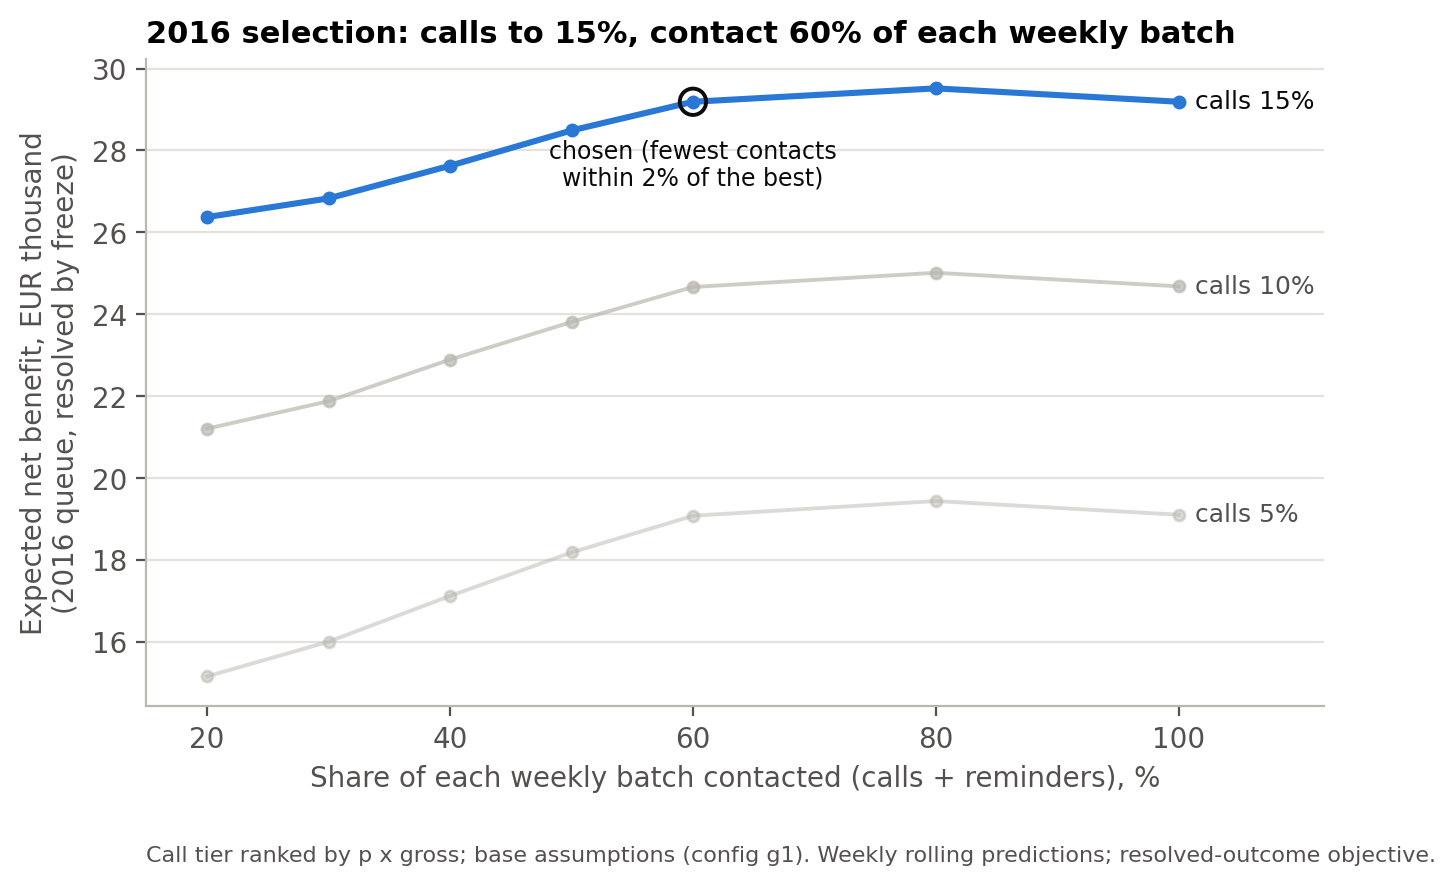

In [6]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
sub = GRID16[GRID16['high_rank'].eq(POLICY['high_rank'])]
hs = sorted(sub['h'].unique())
for i, h in enumerate(hs):
    s = sub[sub['h'].eq(h)].sort_values('c')
    is_ch = np.isclose(h, POLICY['high_share'])
    ax.plot(s['c'] * 100, s['net_eur'] / 1000, marker='o', ms=4, lw=2.2 if is_ch else 1.4,
            color=ACCENT if is_ch else MUTED, alpha=1 if is_ch else 0.5 + 0.2 * i, zorder=3 if is_ch else 2)
    ax.annotate(f'calls {h:.0%}', (s['c'].iloc[-1] * 100, s['net_eur'].iloc[-1] / 1000), xytext=(6, 0),
                textcoords='offset points', va='center', fontsize=9, color=INK if is_ch else INK2)
ax.scatter([POLICY['contact_share'] * 100], [CHOSEN['net_eur'] / 1000], s=90, facecolor='none', edgecolor=INK, lw=1.4, zorder=4)
ax.annotate('chosen (fewest contacts\nwithin 2% of the best)', (POLICY['contact_share'] * 100, CHOSEN['net_eur'] / 1000), xytext=(0, -30),
            textcoords='offset points', ha='center', fontsize=8.5, color=INK)
ax.set_title(f"2016 selection: calls to {POLICY['high_share']:.0%}, contact {POLICY['contact_share']:.0%} of each weekly batch", fontsize=11)
ax.set_xlabel('Share of each weekly batch contacted (calls + reminders), %')
ax.set_ylabel('Expected net benefit, EUR thousand\n(2016 queue, resolved by freeze)')
ax.grid(axis='y', color=GRID); ax.set_xlim(15, 112)
ax.text(0, -0.24, f"Call tier ranked by {POLICY['high_rank'].replace('_', ' ')}; base assumptions (config g1). Weekly rolling predictions; resolved-outcome objective.",
        transform=ax.transAxes, fontsize=8, color=INK2)
save(fig, 'fig_g1_policy_selection_2016.png')

## 4. Evaluation on the frozen 2017 F queue

F scores, eligible booking IDs, decision dates and default tiers are checked below.
All scenarios apply the daily call-task limit. Benefits and variable costs account for
cancellations before the scheduled contact. Outcome-conditioned values belong only to
the retrospective evaluation, never the operational action queue.


In [7]:
AQ = pd.read_csv(MOD / 'action_queue_2017.csv', parse_dates=['score_time', 'booking_date', 'arrival_date'])
assert AQ['run_id'].nunique() == 1 and AQ['run_id'].iloc[0] == MANIFEST_F['run_id'], 'queue and manifest come from different runs'
qi = AQ[AQ['track'].eq('individual model')]
cols = [c for c in P.columns if c not in ('booking_date', 'arrival_date', 'gross_value', 'market_segment', 'lead_time', 'total_nights', 'customer_type')]
base17 = qi[['booking_id', 'score_time', 'booking_date', 'arrival_date', 'gross_value', 'market_segment', 'lead_time',
             'total_nights', 'customer_type', 'p_cancel', 'risk_tier']].merge(P[cols], on='booking_id', how='left', validate='one_to_one')
Q17 = build_queue(base17, base17['p_cancel'], base17['score_time'])
assert len(Q17) == len(qi), 'every queued booking must still pass the eligibility check'
assert (Q17['days'] == qi.set_index('booking_id').loc[Q17['booking_id'], 'days_to_arrival'].to_numpy()).all()
W17 = Q17['batch'].nunique()

# reproduce F's tiers exactly with the G1 tier function (h = 5%, c = 20%, ranked by p)
t_f = make_tiers(Q17, 0.05, 0.20, 'p_cancel')
assert (t_f == Q17['risk_tier'].to_numpy()).all(), 'G1 tiering does not reproduce notebook 04 tiers'

# segment x lead-band rule fitted on individual arrivals up to the fit date, ranked in the same batches
fit_final = P[P['population'].eq('individual') & P['arrival_date'].le(MANIFEST_F['config']['fit_date_final'])]
Q17['rule_score'] = fm.RateTableRule(['market_segment', 'lead_band']).fit(fit_final).predict(Q17)
Qr = Q17.assign(p=Q17['rule_score'])
t_rule = make_tiers(Qr, 0.05, 0.20, 'p_cancel')
tp_rule = int(((t_rule != 'low') & Q17['is_canceled'].eq(1)).sum()); tp_model = int(((t_f != 'low') & Q17['is_canceled'].eq(1)).sum())
print(f'2017 queue: {len(Q17):,} bookings, {W17} weekly batches, cancellation rate {Q17["is_canceled"].mean():.1%}; '
      f'top-20% cancellations model {tp_model} vs rule {tp_rule} (notebook 04 §7.1: 989 vs 850)')

t_g1 = make_tiers(Q17, POLICY['high_share'], POLICY['contact_share'], POLICY['high_rank'])
SIM = {
    'S1 Reminders for all': simulate(Q17, np.full(len(Q17), 'medium')),
    'S2 Rule-based tiers (5% / 20%)': simulate(Qr, t_rule),
    'S3 Model tiers, F default (5% / 20%)': simulate(Q17, t_f),
    'S4 G1 policy': simulate(Q17, t_g1),
}
SCEN = pd.DataFrame([{'scenario': 'S0 Status quo', 'calls': 0, 'actual_calls': 0, 'reminder_bookings': 0, 'messages': 0, 'cancellations_reachable': 0,
                      'prevented_expected': 0.0, 'induced_expected': 0.0, 'benefit_eur': 0.0, 'backfire_loss_eur': 0.0,
                      'variable_cost_eur': 0.0, 'net_eur': 0.0, 'weeks': W17, 'net_eur_per_year': 0.0}]
                    + [summary(s, k, W17) for k, s in SIM.items()]).set_index('scenario')
display(SCEN.round(1))

# value of the model at the G1 policy: the same shares and ranking logic, scored by the rule instead
Qr = Qr.assign(p_x_gross=Qr['p'] * Qr['gross_value'])
t_rule_g1 = make_tiers(Qr, POLICY['high_share'], POLICY['contact_share'], POLICY['high_rank'])
ML_VS_RULE = pd.DataFrame([summary(SIM['S4 G1 policy'], 'G1 shares, model ranking (S4)', W17),
                           summary(simulate(Qr, t_rule_g1), 'G1 shares, segment x lead-band rule ranking', W17)]).set_index('scenario')
display(ML_VS_RULE[['calls', 'reminder_bookings', 'prevented_expected', 'benefit_eur', 'net_eur', 'net_eur_per_year']].round(0))

2017 queue: 12,102 bookings, 35 weekly batches, cancellation rate 24.0%; top-20% cancellations model 989 vs rule 850 (notebook 04 §7.1: 989 vs 850)


,calls,actual_calls,reminder_bookings,messages,cancellations_reachable,prevented_expected,induced_expected,benefit_eur,backfire_loss_eur,variable_cost_eur,net_eur,weeks,net_eur_per_year
scenario,,,,,,,,,,,,,
S0 Status quo,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,35,0.0
S1 Reminders for all,0,0,10703,16738,1286,38.6,39.3,7880.9,4963.2,836.9,2080.8,35,3091.5
S2 Rule-based tiers (5% / 20%),586,586,1810,2583,377,27.3,5.9,4648.0,706.0,955.4,2986.5,35,4437.1
"S3 Model tiers, F default (5% / 20%)",574,570,1803,2561,564,35.4,5.4,10074.4,658.8,931.8,8483.8,35,12604.6
S4 G1 policy,1744,1688,5186,7709,1396,85.6,17.4,25001.5,1781.4,2765.5,20454.5,35,30389.6


,calls,reminder_bookings,prevented_expected,benefit_eur,net_eur,net_eur_per_year
scenario,,,,,,
"G1 shares, model ranking (S4)",1744,5186,86.0,25001.0,20455.0,30390.0
"G1 shares, segment x lead-band rule ranking",1753,5298,80.0,23908.0,19398.0,28819.0


## 5. Group track: earlier release of blocks (simple estimate)

Group blocks follow rules, not the model (decision table G1–G5). The estimate values only rule G1 (ask the agent to confirm or release 30 days before arrival when the group rule flags the block) and only through **resale**: a block that would have cancelled late (under 30 days' notice, or a no-show) and is released at the ask moves from its late resale probability to the 30+ day one (`operations.resale_probability`, by demand). Cost = revenue-manager review time for every flagged block. Price changes (G5) are not costed. Overbooking (G3) is costed separately in the exploratory room-night analysis below using assumed relocation costs; it remains disabled and is not included in S5.

In [8]:
GT = G['group_track']
qg = AQ[AQ['track'].eq('group rule')][['booking_id', 'score_time', 'days_to_arrival', 'p_cancel']].merge(P, on='booking_id', how='left')
ask = qg['arrival_date'] - pd.to_timedelta(GT['release_ask_days'], 'D')
flag_g = qg['p_cancel'].ge(GT['flag_threshold']) & qg['days_to_arrival'].gt(GT['release_ask_days'])
late = qg['is_canceled'].eq(1) & (qg['reservation_status'].eq('No-Show') | qg['reservation_status_date'].gt(ask))
notice_actual = np.where(qg['reservation_status'].eq('No-Show'), -1, (qg['arrival_date'] - qg['reservation_status_date']).dt.days)
p_actual = np.where(notice_actual < 0, 0.0, resale_prob(notice_bucket(notice_actual), qg['demand']))
p_early = resale_prob(np.full(len(qg), 'notice_30_plus'), qg['demand'])

def group_value(share=GT['release_success_share']['value'], minutes=GT['review_minutes_per_booking']['value'],
                rm_hour=GT['revenue_manager_cost_per_hour']['value'], resale_scale=1.0):
    gain = (flag_g & late) * share * (p_early - p_actual) * qg['resale_unit_value'] * resale_scale
    cost = flag_g * minutes / 60 * rm_hour
    return float(gain.sum()), float(cost.sum())

g_gain, g_cost = group_value()
GROUP = {'group_bookings_in_queue': len(qg), 'flagged_for_review': int(flag_g.sum()), 'late_cancellations_among_flagged': int((flag_g & late).sum()),
         'expected_extra_resale_contribution_eur': g_gain, 'review_cost_eur': g_cost, 'net_eur': g_gain - g_cost,
         'net_eur_per_year': (g_gain - g_cost) * G['weeks_per_year'] / W17}
display(pd.Series(GROUP).round(1))
s5 = SCEN.loc['S4 G1 policy'].copy()
s5[['benefit_eur', 'variable_cost_eur', 'net_eur', 'net_eur_per_year']] += [g_gain, g_cost, g_gain - g_cost, GROUP['net_eur_per_year']]
SCEN.loc['S5 G1 policy + group track'] = s5
SCEN['cost_per_prevented_eur'] = SCEN['variable_cost_eur'] / SCEN['prevented_expected'].replace(0, np.nan)
display(SCEN[['calls', 'reminder_bookings', 'messages', 'prevented_expected', 'induced_expected', 'benefit_eur', 'backfire_loss_eur',
              'variable_cost_eur', 'net_eur', 'net_eur_per_year']].round(0))

group_bookings_in_queue                   1054.0
flagged_for_review                         195.0
late_cancellations_among_flagged            37.0
expected_extra_resale_contribution_eur    1207.2
review_cost_eur                            487.5
net_eur                                    719.7
net_eur_per_year                          1069.3
dtype: float64

,calls,reminder_bookings,messages,prevented_expected,induced_expected,benefit_eur,backfire_loss_eur,variable_cost_eur,net_eur,net_eur_per_year
scenario,,,,,,,,,,
S0 Status quo,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
S1 Reminders for all,0.0,10703.0,16738.0,39.0,39.0,7881.0,4963.0,837.0,2081.0,3092.0
S2 Rule-based tiers (5% / 20%),586.0,1810.0,2583.0,27.0,6.0,4648.0,706.0,955.0,2987.0,4437.0
"S3 Model tiers, F default (5% / 20%)",574.0,1803.0,2561.0,35.0,5.0,10074.0,659.0,932.0,8484.0,12605.0
S4 G1 policy,1744.0,5186.0,7709.0,86.0,17.0,25001.0,1781.0,2766.0,20455.0,30390.0
S5 G1 policy + group track,1744.0,5186.0,7709.0,86.0,17.0,26209.0,1781.0,3253.0,21174.0,31459.0


## 5b. Capacity track: overbooking from expected cancellations (rule G3)

**Question.** If the revenue manager lets the hotel sell a few rooms beyond a room type's capacity on nights when it is fully booked, because the model expects some of those bookings to cancel, how much is earned net of walked guests?

**Rule tested (room type × stay night).** At `L` days before the night, take every booking still active for that night. Expected cancellations from then on = sum of each booking's probability of cancelling after that date (`q`, calibrated on 2016 by model-score decile for individuals, the average individual rate for the few individual bookings without a model score, and by segment × deposit cell for group blocks). Expected free rooms = capacity − on the books + expected cancellations − expected late pick-up (2016 average). If the room type is fully booked on the books, the limit is `floor(expected free − k × sd)`, at most `cap_share` of its rooms. Approved extra rooms are sold with probability `sell_through`; a guest who arrives to no room is walked at `walk_cost` plus the lost stay. `L` and `k` are chosen on 2016 nights, then 2017 nights are scored once, against a naive version that uses one average cancellation rate for every booking.

Capacity is the derived peak per room type (`operations.room_capacity_by_type`); realised rooms sold are the simulated inventory table, so the result is a retrospective prototype.

In [9]:
from scipy.stats import binom
OB = G['overbooking']
P['population'] = P['population'].fillna('individual')
inv = ops[ops['room_type'].ne('P')].set_index(['stay_date', 'room_type'])

# 1. Does the hotel ever sell out? (derived capacity, realised rooms sold)
hot = inv.groupby(level='stay_date')[['available_rooms', 'rooms_sold']].sum()
hot = hot.loc['2016-01-01':'2017-08-31']
occ_h = hot['rooms_sold'] / hot['available_rooms']
SELLOUT = {'nights': len(hot), 'max_hotel_occupancy': occ_h.max(), 'nights_occupancy_ge_85pct': int((occ_h >= 0.85).sum()),
           'min_free_rooms_any_night': int((hot['available_rooms'] - hot['rooms_sold']).min())}

def all_scores(fit_date, ind_p):
    p = pd.Series(np.nan, index=P['booking_id'].to_numpy())
    p.loc[ind_p.index] = ind_p.to_numpy()
    grp = P[P['population'].eq('group_block')]
    p.loc[grp['booking_id'].to_numpy()] = fm.RateTableRule(['market_segment', 'deposit_type'], m=30).fit(
        grp[grp['arrival_date'].le(fit_date)]).predict(grp)
    return p
tp17 = pd.read_csv(MOD / 'test_predictions_2017.csv').set_index('booking_id')['p_cancel']
p16 = all_scores(MANIFEST_F['config']['folds'][0][1], oof.set_index('booking_id')['p_cancel'])   # rule fitted before fold 1
p17 = all_scores(MANIFEST_F['config']['fit_date_final'], tp17)

bk = P[P['total_nights'] > 0][['booking_id', 'booking_date', 'arrival_date', 'total_nights', 'is_canceled', 'reservation_status',
                               'reservation_status_date', 'reserved_room_type', 'population', 'market_segment', 'deposit_type']].reset_index(drop=True)
NIGHTS = bk.loc[bk.index.repeat(bk['total_nights'])].copy()
NIGHTS['night'] = NIGHTS['arrival_date'] + pd.to_timedelta(NIGHTS.groupby(level=0).cumcount(), 'D')
NIGHTS = NIGHTS[NIGHTS['reserved_room_type'].ne('P')].reset_index(drop=True)

# 2. Room type A: reservations held vs rooms (7 days before the night)
nA = NIGHTS[NIGHTS['reserved_room_type'].eq('A') & NIGHTS['night'].between('2016-01-01', '2017-08-31')]
TA = nA['night'] - pd.Timedelta(days=7)
actA = nA['booking_date'].le(TA) & ~(nA['reservation_status'].eq('Canceled') & nA['reservation_status_date'].le(TA))
otbA = nA[actA].groupby('night').size()
capA = inv.xs('A', level='room_type').reindex(otbA.index)
fullA = otbA >= capA['available_rooms']
stay_nights = NIGHTS[NIGHTS['is_canceled'].eq(0)].merge(P[['booking_id', 'assigned_room_type']], on='booking_id')
SELLOUT.update({'type_A_nights_more_reservations_than_rooms_7d_before': int(fullA.sum()),
                'type_A_mean_reservations_on_those_nights': otbA[fullA].mean(), 'type_A_rooms': int(capA['available_rooms'].max()),
                'type_A_mean_free_rooms_on_those_nights': (capA['available_rooms'] - capA['rooms_sold'])[fullA].mean(),
                'reserved_A_stays_moved_to_another_type': (stay_nights.loc[stay_nights['reserved_room_type'].eq('A'), 'assigned_room_type'] != 'A').mean()})
display(pd.Series(SELLOUT).round(3))

nights                                                  609.000
max_hotel_occupancy                                       0.897
nights_occupancy_ge_85pct                               227.000
min_free_rooms_any_night                                 26.000
type_A_nights_more_reservations_than_rooms_7d_before    198.000
type_A_mean_reservations_on_those_nights                154.561
type_A_rooms                                            146.000
type_A_mean_free_rooms_on_those_nights                    9.242
reserved_A_stays_moved_to_another_type                    0.147
dtype: float64

### 5b. Exploratory overbooking sensitivity — G3 disabled

This separate retrospective room-night experiment retains F's original arrival-fold OOF
scores and derived inventory assumptions. It is not a validated operational score-time
contract and must not produce executable overbooking actions. The calculated values are
diagnostics only. G3 remains explicitly disabled in configuration, policy and rule exports,
regardless of the best grid row; enabling it requires a new approved capacity design.


In [10]:
def night_frame(L, p, lo, hi):
    n = NIGHTS[NIGHTS['night'].between(lo, hi)].copy()
    T = n['night'] - pd.Timedelta(days=L)
    created = n['booking_date'].le(T)
    active = created & ~(n['reservation_status'].eq('Canceled') & n['reservation_status_date'].le(T))
    n['at_risk'] = active & n['arrival_date'].gt(T)
    n['active'] = active
    n['p'] = p.reindex(n['booking_id']).to_numpy()
    n['cancel_after'] = n['is_canceled'].eq(1) & active
    n['pickup_stay'] = ~created & n['is_canceled'].eq(0)
    return n

def calibrate_q(n, bins=10):
    d_all = n[n['at_risk'] & n['population'].eq('individual')]
    d = d_all[d_all['p'].notna()]   # unscored nights would turn every decile edge into NaN (all individuals in one bin)
    edges = np.quantile(d['p'], np.linspace(0, 1, bins + 1))
    r_ind = d.groupby(np.clip(np.searchsorted(edges[1:-1], d['p'], side='right'), 0, bins - 1))['cancel_after'].mean().reindex(range(bins)).to_numpy()
    g = n[n['at_risk'] & n['population'].eq('group_block')]
    return {'edges': edges, 'r_ind': r_ind, 'r_grp': g.groupby(['market_segment', 'deposit_type'])['cancel_after'].mean(),
            'grp_mean': g['cancel_after'].mean(), 'ind_mean': d_all['cancel_after'].mean(), 'naive': n.loc[n['at_risk'], 'cancel_after'].mean()}

def q_of(n, cal, naive=False):
    risk = n['at_risk'].to_numpy()
    if naive:
        return np.where(risk, cal['naive'], 0.0)
    q = np.zeros(len(n))
    ind = risk & n['population'].eq('individual').to_numpy()
    scored = ind & n['p'].notna().to_numpy()
    q[scored] = cal['r_ind'][np.clip(np.searchsorted(cal['edges'][1:-1], n.loc[scored, 'p'].to_numpy(), side='right'), 0, len(cal['r_ind']) - 1)]
    q[ind & ~scored] = cal['ind_mean']   # individual booking without a model score: average individual rate
    grp = risk & n['population'].eq('group_block').to_numpy()
    q[grp] = cal['r_grp'].reindex(pd.MultiIndex.from_frame(n.loc[grp, ['market_segment', 'deposit_type']])).fillna(cal['grp_mean']).to_numpy()
    return q

adr_m = P[P['is_canceled'].eq(0)].assign(m=lambda d: d['arrival_date'].dt.to_period('M'))
ADR_M = adr_m.groupby(['reserved_room_type', 'm'])['adr_clean'].median()
COST_M = adr_m.groupby(['reserved_room_type', 'm'])['syn_room_cost_per_night'].median()

def overbook(n, q, k, pick, sell=OB['sell_through']['value'], walk=OB['walk_cost']['value'], cap=OB['cap_share']):
    g = n.assign(q=q, v=q * (1 - q)).groupby(['night', 'reserved_room_type'])
    d = pd.DataFrame({'otb': g['active'].sum(), 'E': g['q'].sum(), 'var': g['v'].sum()})
    d.index = d.index.set_names(['stay_date', 'room_type'])
    d = d.join(inv[['available_rooms', 'rooms_sold']], how='inner')
    d = d[d['available_rooms'] > 0]
    rt = d.index.get_level_values('room_type')
    free_hat = d['available_rooms'] - d['otb'] + d['E'] - rt.map(pick['mean']).to_numpy()
    sd = np.sqrt(d['var'] + rt.map(pick['var']).to_numpy())
    lim = np.minimum(np.floor(free_hat - k * sd).clip(lower=0), np.floor(cap * d['available_rooms']))
    d['limit'] = np.where(d['otb'] >= d['available_rooms'], lim, 0).astype(int)
    free_act = (d['available_rooms'] - d['rooms_sold']).clip(lower=0).to_numpy()
    sold, walks = np.zeros(len(d)), np.zeros(len(d))
    for i in np.flatnonzero(d['limit'].to_numpy()):
        x = np.arange(d['limit'].iat[i] + 1); pm = binom.pmf(x, d['limit'].iat[i], sell)
        sold[i], walks[i] = (x * pm).sum(), (np.maximum(0, x - free_act[i]) * pm).sum()
    keys = pd.MultiIndex.from_arrays([rt, pd.PeriodIndex(d.index.get_level_values('stay_date'), freq='M')])
    contrib = ADR_M.reindex(keys).to_numpy() * OPS['resale_price_factor']['value'] * (1 - resale_comm) - COST_M.reindex(keys).to_numpy()
    contrib = np.nan_to_num(contrib, nan=np.nanmedian(contrib))
    d['extra_sold'], d['walks'] = sold, walks
    d['net'] = (sold - walks) * contrib - walks * walk
    return d

def ob_summary(d, label, nights_in_period):
    return {'policy': label, 'nights_with_limit': int((d['limit'] > 0).sum()), 'rooms_offered': int(d['limit'].sum()),
            'extra_sold': d['extra_sold'].sum(), 'walks': d['walks'].sum(), 'net_eur': d['net'].sum(),
            'net_eur_per_year': d['net'].sum() * 365 / nights_in_period}

ob_rows, OB_CAL = [], {}
for L in OB['decision_lead_days_grid']:
    n16 = night_frame(L, p16, '2016-04-01', '2016-12-31')
    cal = calibrate_q(n16)
    pk = n16.groupby(['night', 'reserved_room_type'])['pickup_stay'].sum().unstack(fill_value=0)
    OB_CAL[L] = (cal, {'mean': pk.mean(), 'var': pk.var()})
    for k in OB['safety_k_grid']:
        r = ob_summary(overbook(n16, q_of(n16, cal), k, OB_CAL[L][1]), f'L={L}, k={k}', 275)
        ob_rows.append({**r, 'L': L, 'k': k})
OB_GRID16 = pd.DataFrame(ob_rows)
best_ob = OB_GRID16.sort_values(['net_eur', 'walks'], ascending=[False, True]).iloc[0]
OB_POLICY = {'L': int(best_ob['L']), 'k': float(best_ob['k'])}
display(OB_GRID16[['L', 'k', 'nights_with_limit', 'rooms_offered', 'extra_sold', 'walks', 'net_eur']].round(1))
print('Chosen on 2016 (highest net):', OB_POLICY)
print(f"Individual q by model-score decile (2016, L={OB_POLICY['L']}):", np.round(OB_CAL[OB_POLICY['L']][0]['r_ind'], 3))

n17 = night_frame(OB_POLICY['L'], p17, '2017-01-01', '2017-08-31')
cal, pk = OB_CAL[OB_POLICY['L']]
nights17 = n17['night'].nunique()
OB17 = pd.DataFrame([ob_summary(overbook(n17, q_of(n17, cal), OB_POLICY['k'], pk), 'model q (chosen policy)', nights17),
                     ob_summary(overbook(n17, q_of(n17, cal, naive=True), OB_POLICY['k'], pk), 'naive average q', nights17)]).set_index('policy')
for w in OB['walk_cost']['sensitivity_range']:
    OB17.loc[f'model q, walk cost EUR {w}'] = ob_summary(overbook(n17, q_of(n17, cal), OB_POLICY['k'], pk, walk=w), '', nights17)
exp_late, act_late = q_of(n17, cal)[n17['at_risk'].to_numpy()].sum(), int(n17.loc[n17['at_risk'], 'cancel_after'].sum())
display(OB17.round(1))
print(f'2017 check: expected cancelled room-nights after the decision date {exp_late:,.0f} vs actual {act_late:,}')

Chosen on 2016 (highest net): {'L': 30, 'k': 0.0}
Individual q by model-score decile (2016, L=30): [0.044 0.075 0.057 0.07  0.145 0.199 0.191 0.196 0.213 0.308]
2017 check: expected cancelled room-nights after the decision date 6,770 vs actual 5,805


,L,k,nights_with_limit,rooms_offered,extra_sold,walks,net_eur
0,7,0.0,3,4,3.2,0.0,190.2
1,7,0.5,0,0,0.0,0.0,0.0
2,7,1.0,0,0,0.0,0.0,0.0
3,7,1.5,0,0,0.0,0.0,0.0
4,7,2.0,0,0,0.0,0.0,0.0
5,14,0.0,7,10,8.0,1.6,139.5
6,14,0.5,0,0,0.0,0.0,0.0
7,14,1.0,0,0,0.0,0.0,0.0
8,14,1.5,0,0,0.0,0.0,0.0
9,14,2.0,0,0,0.0,0.0,0.0


,nights_with_limit,rooms_offered,extra_sold,walks,net_eur,net_eur_per_year
policy,,,,,,
model q (chosen policy),3,11,8.8,4.6,-454.6,-682.8
naive average q,0,0,0.0,0.0,0.0,0.0
"model q, walk cost EUR 75",3,11,8.8,4.6,-109.6,-164.6
"model q, walk cost EUR 300",3,11,8.8,4.6,-1144.6,-1719.3


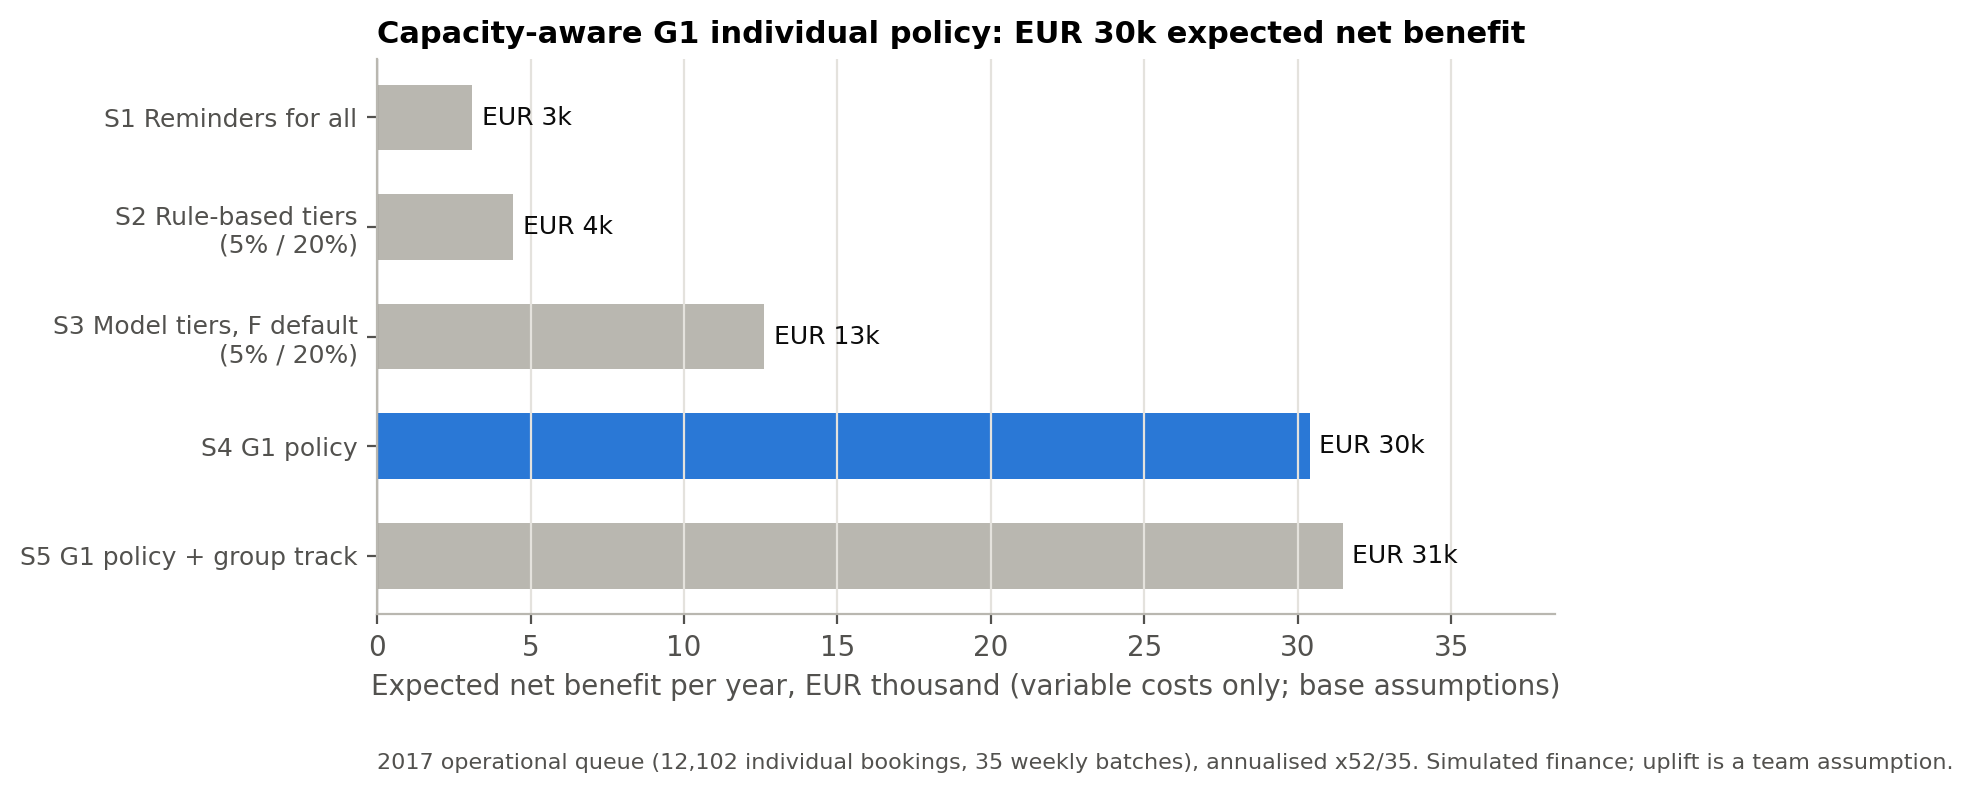

In [11]:
order = ['S1 Reminders for all', 'S2 Rule-based tiers (5% / 20%)', 'S3 Model tiers, F default (5% / 20%)', 'S4 G1 policy', 'S5 G1 policy + group track']
vals = SCEN.loc[order, 'net_eur_per_year'] / 1000
fig, ax = plt.subplots(figsize=(7.6, 3.6))
colors = [ACCENT if k.startswith('S4') else MUTED for k in order]
bars = ax.barh(range(len(order))[::-1], vals, color=colors, height=0.6)
for y, v in zip(range(len(order))[::-1], vals):
    ax.text(v + vals.max() * 0.01, y, f'EUR {v:,.0f}k', va='center', fontsize=9, color=INK)
ax.set_yticks(range(len(order))[::-1], [o.replace(' (5% / 20%)', '\n(5% / 20%)') for o in order], fontsize=9)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_title(f"Capacity-aware G1 individual policy: EUR {SCEN.loc['S4 G1 policy', 'net_eur_per_year'] / 1000:,.0f}k expected net benefit", fontsize=11)
ax.set_xlabel('Expected net benefit per year, EUR thousand (variable costs only; base assumptions)')
ax.grid(axis='x', color=GRID); ax.set_xlim(min(0, vals.min() * 1.1), vals.max() * 1.22)
ax.text(0, -0.28, f'2017 operational queue ({len(Q17):,} individual bookings, {W17} weekly batches), annualised x{G["weeks_per_year"]}/{W17}. '
        'Simulated finance; uplift is a team assumption.', transform=ax.transAxes, fontsize=8, color=INK2)
save(fig, 'fig_g1_scenarios_2017.png')

## 6. Sensitivity and break-even

The following results use the same dated call schedule as the base scenario. Uplift,
backfire, costs and resale assumptions vary while the chosen policy stays frozen.


In [12]:
def s4_net(prm=BASE, policy_tiers=t_g1):
    return simulate(Q17, policy_tiers, prm)['net'].sum() * G['weeks_per_year'] / W17

base_net = s4_net()
tests = [('Call uplift', 'uplift_call', G['uplift']['sensitivity_range']['phone_call']),
         ('Reminder uplift', 'uplift_rem', G['uplift']['sensitivity_range']['reminder']),
         ('Reminder backfire', 'backfire_rem', G['backfire']['sensitivity_range']['reminder']),
         ('Call backfire', 'backfire_call', G['backfire']['sensitivity_range']['phone_call']),
         ('Resale of cancelled rooms (x)', 'resale_scale', G['resale_scale']['sensitivity_range']),
         ('SMS price (EUR)', 'sms_cost', G['sms_cost_per_message']['sensitivity_range']),
         ('Call minutes per attempt', 'call_minutes', G['call_minutes_per_attempt']['sensitivity_range']),
         ('Call attempts per booking', 'call_attempts', G['call_attempts_per_booking']['sensitivity_range'])]
rows = []
for name, key, (lo, hi) in tests:
    rows.append({'assumption': name, 'base': BASE[key], 'low': lo, 'high': hi,
                 'net_at_low': s4_net({**BASE, key: lo}), 'net_at_high': s4_net({**BASE, key: hi})})
SENS = pd.DataFrame(rows)
SENS['swing'] = (SENS['net_at_high'] - SENS['net_at_low']).abs()
SENS = SENS.sort_values('swing', ascending=False).reset_index(drop=True)
display(SENS.round(3))

# break-even uplift per channel (S4 tiers): uplift at which that channel's net = 0
sim0 = simulate(Q17, t_g1, {**BASE, 'uplift_call': 1.0, 'uplift_rem': 1.0})       # benefit at uplift 1 = value reachable
simb = simulate(Q17, t_g1)
BREAK = {}
for ch, m in [('phone_call', simb['call']), ('reminder', simb['reminder'])]:
    reach = sim0.loc[m, 'benefit'].sum(); burden = simb.loc[m, 'cost'].sum() + simb.loc[m, 'backfire_loss'].sum()
    BREAK[ch] = {'value_reachable_eur_at_full_prevention': reach, 'cost_plus_backfire_eur': burden, 'break_even_uplift': burden / reach,
                 'assumed_uplift': BASE['uplift_call' if ch == 'phone_call' else 'uplift_rem']}
BREAK = pd.DataFrame(BREAK).T
display(BREAK.round(4))

# uplift multiplier: all uplifts scaled together, policies held fixed
ks = np.linspace(0, 2, 21)
CURVE = pd.DataFrame({k: [simulate(Q17, t, {**BASE, 'uplift_call': BASE['uplift_call'] * m, 'uplift_rem': BASE['uplift_rem'] * m})['net'].sum()
                          * G['weeks_per_year'] / W17 for m in ks]
                      for k, t in [('S1 Reminders for all', np.full(len(Q17), 'medium')), ('S3 Model tiers, F default', t_f), ('S4 G1 policy', t_g1)]},
                     index=ks)

,assumption,base,low,high,net_at_low,net_at_high,swing
0,Call uplift,0.100,0.00,0.25,-1879.849,78793.730,80673.579
1,Resale of cancelled rooms (x),1.000,0.50,1.50,40297.113,20482.052,19815.061
2,Reminder uplift,0.030,0.00,0.08,25513.930,38515.671,13001.741
3,Reminder backfire,0.005,0.00,0.02,33036.297,22449.438,10586.859
4,Call backfire,0.000,0.00,0.01,30389.583,26489.674,3899.909
5,Call minutes per attempt,6.000,4.00,10.00,31568.289,28032.170,3536.119
6,Call attempts per booking,1.500,1.00,2.00,31568.289,29210.876,2357.413
7,SMS price (EUR),0.050,0.02,0.10,30733.184,29816.914,916.270


,value_reachable_eur_at_full_prevention,cost_plus_backfire_eur,break_even_uplift,assumed_uplift
phone_call,217198.098,2380.0800,0.0110,0.10
reminder,109389.651,2166.8926,0.0198,0.03


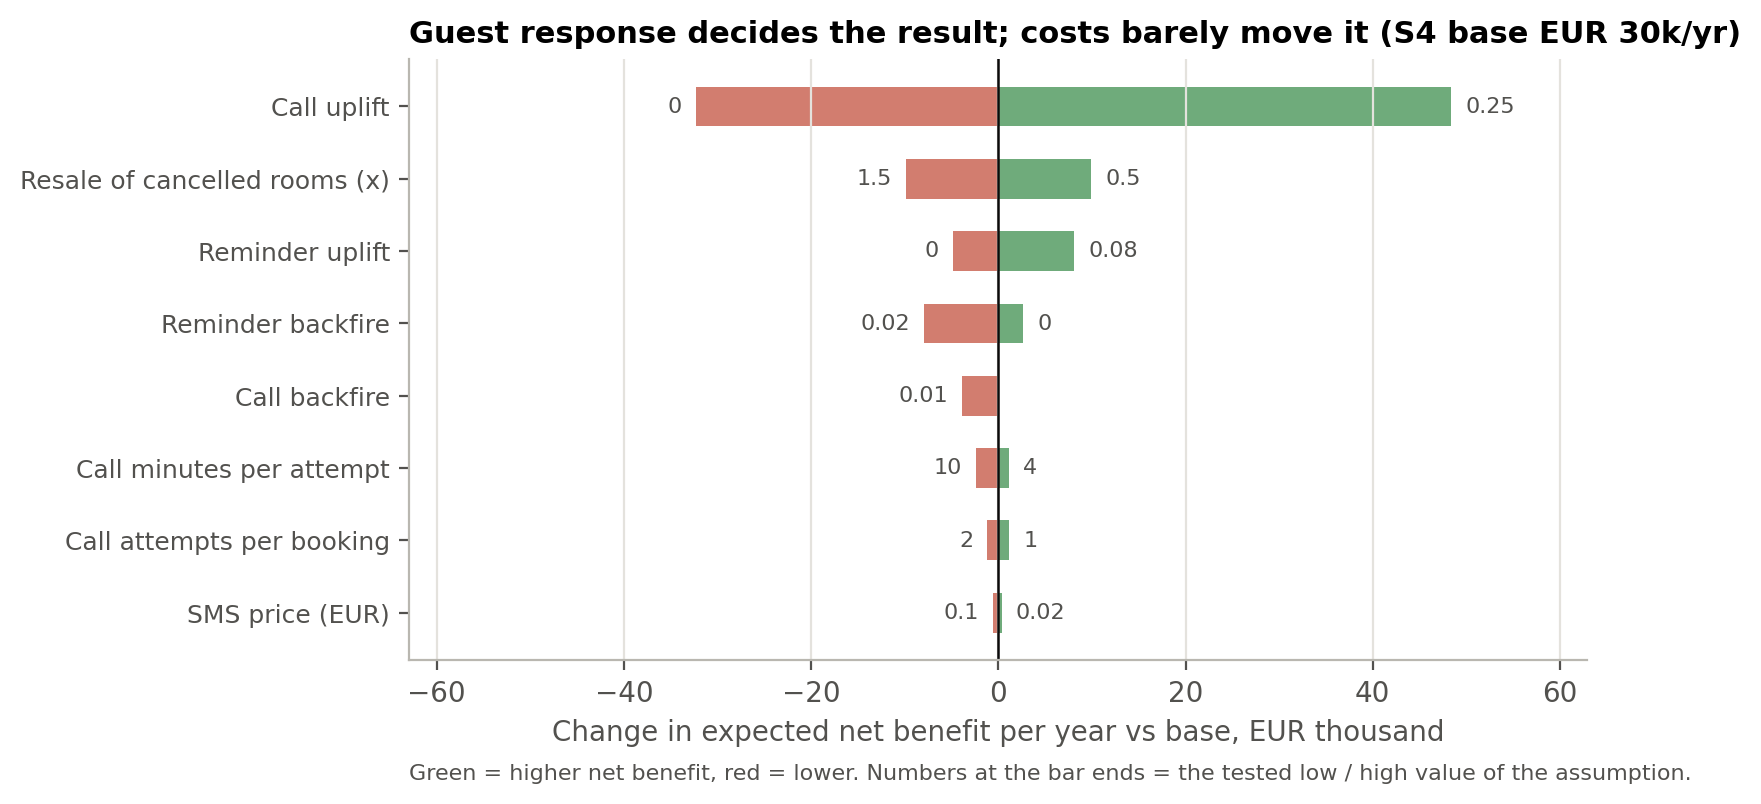

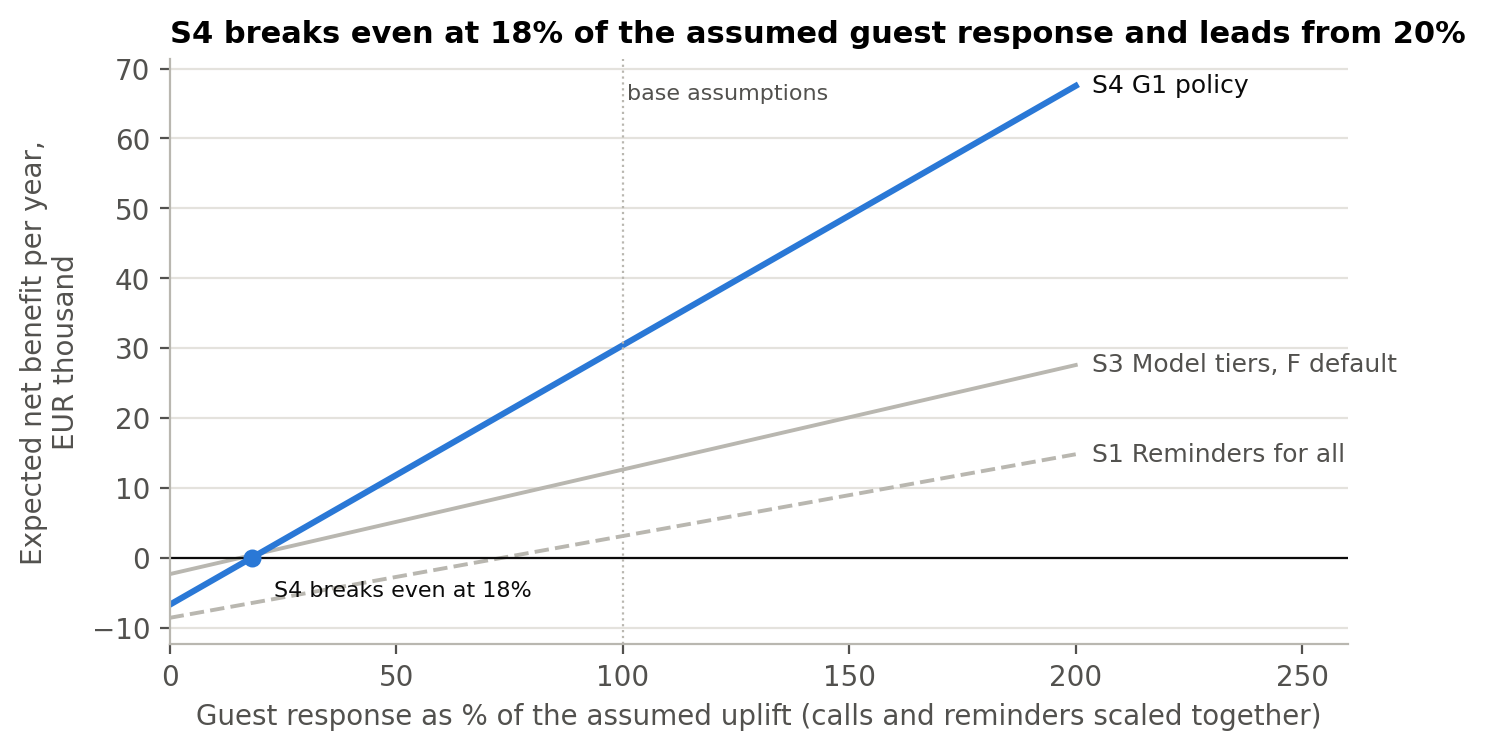

In [13]:
fig, ax = plt.subplots(figsize=(7.6, 3.9))
S = SENS.iloc[::-1]
y = np.arange(len(S))
for yi, (_, r) in zip(y, S.iterrows()):
    lo, hi = (r['net_at_low'] - base_net) / 1000, (r['net_at_high'] - base_net) / 1000
    for v in (lo, hi):
        ax.barh(yi, v, color=GOOD if v > 0 else BAD, alpha=0.75, height=0.55)
    for v, lab in ((lo, r['low']), (hi, r['high'])):
        if abs(v) > 1e-9:
            ax.text(v + (1.5 if v > 0 else -1.5), yi, f"{lab:g}", va='center', ha='left' if v > 0 else 'right', fontsize=8, color=INK2)
ax.set_yticks(y, S['assumption'], fontsize=9)
ax.axvline(0, color=INK, lw=0.9)
ax.set_title(f'Guest response decides the result; costs barely move it (S4 base EUR {base_net / 1000:,.0f}k/yr)', fontsize=11)
ax.set_xlabel('Change in expected net benefit per year vs base, EUR thousand')
ax.grid(axis='x', color=GRID)
pad = max(abs((SENS['net_at_low'] - base_net)).max(), abs((SENS['net_at_high'] - base_net)).max()) / 1000
ax.set_xlim(-pad * 1.3, pad * 1.3)
ax.text(0, -0.2, 'Green = higher net benefit, red = lower. Numbers at the bar ends = the tested low / high value of the assumption.',
        transform=ax.transAxes, fontsize=8, color=INK2)
save(fig, 'fig_g1_sensitivity_tornado.png')

fig, ax = plt.subplots(figsize=(7.6, 3.8))
for k in CURVE.columns:
    is4 = k.startswith('S4')
    ax.plot(CURVE.index * 100, CURVE[k] / 1000, lw=2.2 if is4 else 1.4, color=ACCENT if is4 else MUTED,
            ls='-' if is4 or k.startswith('S3') else '--')
    ax.annotate(k, (200, CURVE[k].iloc[-1] / 1000), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9,
                color=INK if is4 else INK2)
ax.axhline(0, color=INK, lw=0.8); ax.axvline(100, color=MUTED, lw=0.8, ls=':')
ax.text(101, ax.get_ylim()[1] * 0.92, 'base assumptions', fontsize=8, color=INK2)
be4 = np.interp(0, CURVE['S4 G1 policy'], CURVE.index) * 100
cross = CURVE.index[(CURVE['S4 G1 policy'] >= CURVE['S3 Model tiers, F default']).to_numpy()].min() * 100
ax.scatter([be4], [0], s=30, color=ACCENT, zorder=4)
ax.annotate(f'S4 breaks even at {be4:.0f}%', (be4, 0), xytext=(8, -14), textcoords='offset points', fontsize=8, color=INK)
ax.set_title(f'S4 breaks even at {be4:.0f}% of the assumed guest response and leads from {cross:.0f}%', fontsize=11)
ax.set_xlabel('Guest response as % of the assumed uplift (calls and reminders scaled together)')
ax.set_ylabel('Expected net benefit per year,\nEUR thousand')
ax.grid(axis='y', color=GRID); ax.set_xlim(0, 260)
save(fig, 'fig_g1_uplift_curve.png')

## 7. Programme ROI and payback

Annual net benefit is after variable intervention costs. Over Y years, programme net is
Y × (annual net benefit − fixed running cost) − one-off cost. ROI divides this net by
one-off + Y × (fixed running + variable intervention costs). This matches KPI B7.
All values are undiscounted simulations. Payback uses the net cash after running costs.

The 2016-volume sensitivity scales volume arithmetically and is not capacity-revalidated; it is not the executable base case or an approved staffing plan.


In [14]:
PC = G['programme_costs']
one_off = PC['implementation_one_off']['value'] + PC['training_hours_per_staff'] * PC['staff_trained'] * staff_hour
running = 12 * (PC['hosting_per_month']['value'] + PC['monitoring_days_per_month']['value'] * PC['analyst_day_cost']['value'])
Y = PC['horizon_years']
annual_variable = SCEN['variable_cost_eur'] * G['weeks_per_year'] / W17
def case(annual_net, variable=None, one=one_off, run=running):
    variable = annual_variable.loc['S4 G1 policy'] if variable is None else variable
    return gd.programme_case(annual_net, variable, one, run, Y)
BC = pd.DataFrame({k: case(SCEN.loc[k, 'net_eur_per_year'], annual_variable.loc[k]) for k in order}).T
# volume check: the 2017 queue misses far-ahead bookings near the end of the extract, so its weekly pace understates a full
# year. Upper case = 2016 new individual bookings x the eligible share of scored 2017 bookings.
qc = pd.read_csv(MOD / 'queue_contract.csv', index_col=0)
scored = qc.loc[[i for i in qc.index if not str(i).startswith('not scored')], 'individual'].astype(int)
elig_share = scored.loc['eligible (known checks)'] / scored.sum()
VOL_FACTOR = staff['new_individual_bookings'].sum() * elig_share / (len(Q17) * G['weeks_per_year'] / W17)
BC.loc['S4 volume sensitivity (capacity not revalidated)'] = case(SCEN.loc['S4 G1 policy', 'net_eur_per_year'] * VOL_FACTOR, annual_variable.loc['S4 G1 policy'] * VOL_FACTOR)
display(BC.round(2))
print(f'One-off EUR {one_off:,.0f} (implementation + training); running EUR {running:,.0f} a year; '
      f'volume factor {VOL_FACTOR:.2f} (2016 new individual bookings {staff["new_individual_bookings"].sum():,} x eligible share {elig_share:.1%})')

# business-case sensitivity on S4 (programme cost ranges and the two uplifts)
bc_rows = []
for name, one, run, net in [
        ('Implementation one-off', PC['implementation_one_off']['sensitivity_range'], None, None),
        ('Hosting per month', None, PC['hosting_per_month']['sensitivity_range'], None),
        ('Monitoring days per month', None, PC['monitoring_days_per_month']['sensitivity_range'], None),
        ('Analyst day cost', None, PC['analyst_day_cost']['sensitivity_range'], None)]:
    for which, val in zip(['low', 'high'], (one or run)):
        o, r = one_off, running
        if name == 'Implementation one-off': o = val + PC['training_hours_per_staff'] * PC['staff_trained'] * staff_hour
        if name == 'Hosting per month': r = 12 * (val + PC['monitoring_days_per_month']['value'] * PC['analyst_day_cost']['value'])
        if name == 'Monitoring days per month': r = 12 * (PC['hosting_per_month']['value'] + val * PC['analyst_day_cost']['value'])
        if name == 'Analyst day cost': r = 12 * (PC['hosting_per_month']['value'] + PC['monitoring_days_per_month']['value'] * val)
        c_ = case(base_net, one=o, run=r)
        bc_rows.append({'assumption': name, 'value': which, 'roi': c_[f'roi_{Y}y'], 'payback_months': c_['payback_months']})
for name, key in [('Call uplift', 'Call uplift'), ('Reminder uplift', 'Reminder uplift')]:
    r_ = SENS.set_index('assumption').loc[key]
    for which, net in [('low', r_['net_at_low']), ('high', r_['net_at_high'])]:
        c_ = case(net)
        bc_rows.append({'assumption': name, 'value': which, 'roi': c_[f'roi_{Y}y'], 'payback_months': c_['payback_months']})
BC_SENS = pd.DataFrame(bc_rows)
display(BC_SENS.round(2))

One-off EUR 15,564 (implementation + training); running EUR 3,360 a year; volume factor 1.30 (2016 new individual bookings 30,069 x eligible share 77.7%)


,annual_net_benefit_eur,annual_variable_cost_eur,running_cost_eur_per_year,one_off_cost_eur,year1_net_eur,net_3y_eur,total_cost_3y_eur,roi_3y,payback_months
S1 Reminders for all,3091.54,1243.39,3360.0,15564.0,-15832.46,-16369.38,29374.18,-0.56,NaN
S2 Rule-based tiers (5% / 20%),4437.13,1419.47,3360.0,15564.0,-14486.87,-12332.60,29902.40,-0.41,173.39
"S3 Model tiers, F default (5% / 20%)",12604.57,1384.31,3360.0,15564.0,-6319.43,12169.70,29796.94,0.41,20.20
S4 G1 policy,30389.58,4108.79,3360.0,15564.0,11465.58,65524.75,37970.36,1.73,6.91
S5 G1 policy + group track,31458.84,4833.07,3360.0,15564.0,12534.84,68732.53,40143.22,1.71,6.65
S4 volume sensitivity (capacity not revalidated),39491.92,5339.46,3360.0,15564.0,20567.92,92831.76,41662.37,2.23,5.17


,assumption,value,roi,payback_months
0,Implementation one-off,low,2.34,3.80
1,Implementation one-off,high,0.95,13.57
2,Hosting per month,low,1.78,6.85
3,Hosting per month,high,1.58,7.10
4,Monitoring days per month,low,2.08,6.56
5,Monitoring days per month,high,1.22,7.73
6,Analyst day cost,low,1.89,6.73
7,Analyst day cost,high,1.37,7.44
8,Call uplift,low,-0.82,NaN
9,Call uplift,high,5.55,2.48


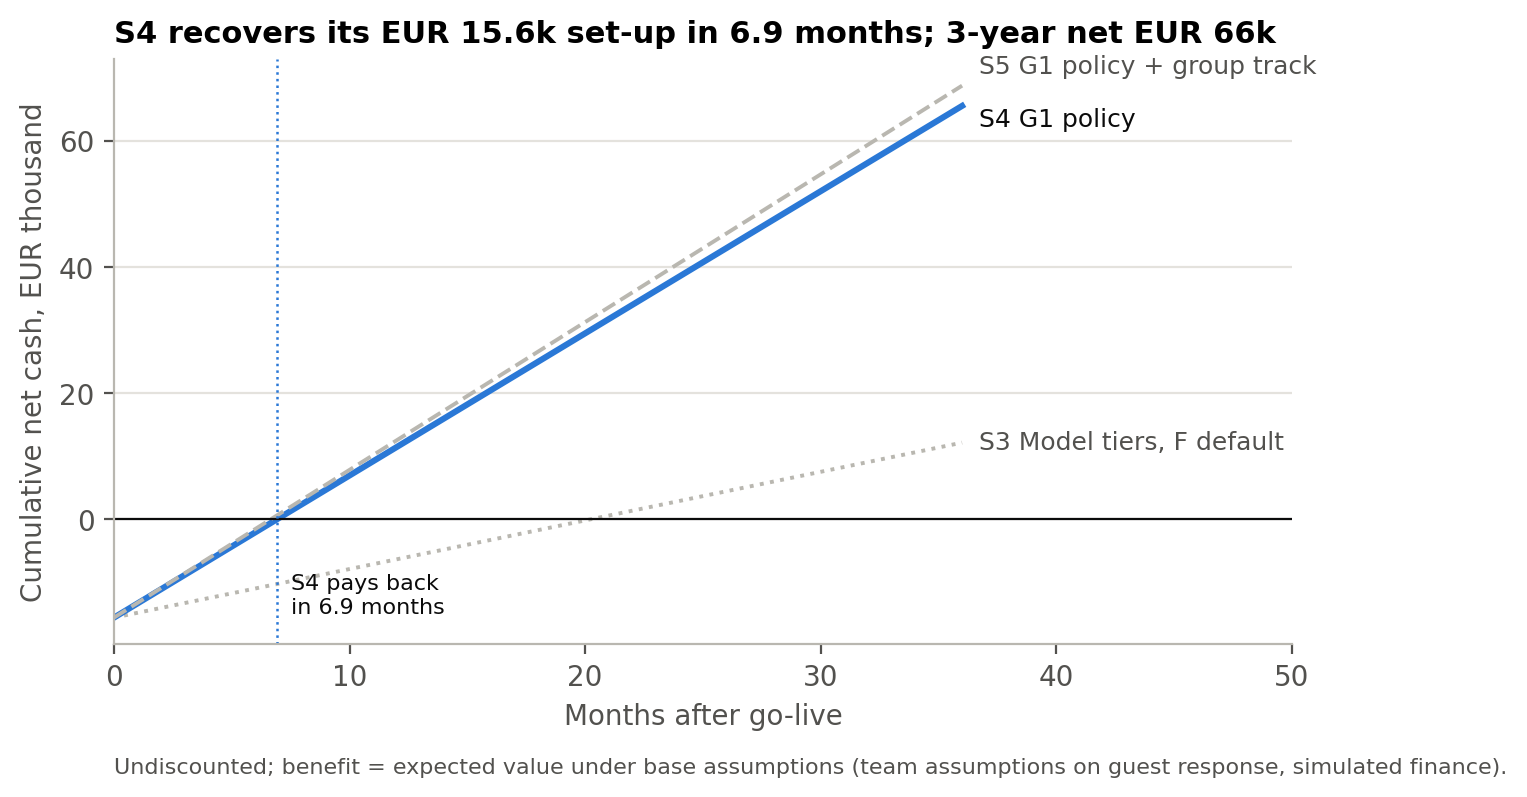

In [15]:
months = np.arange(0, 12 * Y + 1)
fig, ax = plt.subplots(figsize=(7.6, 3.8))
for k in ['S3 Model tiers, F default (5% / 20%)', 'S4 G1 policy', 'S5 G1 policy + group track']:
    r = BC.loc[k]
    cum = -r['one_off_cost_eur'] + months * (r['annual_net_benefit_eur'] - r['running_cost_eur_per_year']) / 12
    is4 = k.startswith('S4')
    ax.plot(months, cum / 1000, lw=2.2 if is4 else 1.4, color=ACCENT if is4 else MUTED, ls='-' if is4 else ('--' if k.startswith('S5') else ':'))
    ax.annotate(k.replace(' (5% / 20%)', ''), (months[-1], cum[-1] / 1000), xytext=(6, 7 if k.startswith('S5') else (-5 if is4 else 0)),
                textcoords='offset points', va='center', fontsize=9, color=INK if is4 else INK2)
ax.axhline(0, color=INK, lw=0.8)
pb = BC.loc['S4 G1 policy', 'payback_months']
ax.axvline(pb, color=ACCENT, lw=0.9, ls=':')
ax.text(pb + 0.6, ax.get_ylim()[0] * 0.75 if ax.get_ylim()[0] < 0 else 2, f'S4 pays back\nin {pb:.1f} months', fontsize=8, color=INK)
ax.set_title(f"S4 recovers its EUR {one_off / 1000:,.1f}k set-up in {pb:.1f} months; {Y}-year net EUR {BC.loc['S4 G1 policy', f'net_{Y}y_eur'] / 1000:,.0f}k", fontsize=11)
ax.set_xlabel('Months after go-live'); ax.set_ylabel('Cumulative net cash, EUR thousand')
ax.grid(axis='y', color=GRID); ax.set_xlim(0, 12 * Y + 14)
ax.text(0, -0.22, 'Undiscounted; benefit = expected value under base assumptions (team assumptions on guest response, simulated finance).',
        transform=ax.transAxes, fontsize=8, color=INK2)
save(fig, 'fig_g1_payback.png')

## 8. Pilot design and KPI references

Randomise before contact and analyse by assigned arm, including missed contacts.
Power calculations below are illustrative under the stated response assumptions.
Unknown outcomes in the 2016 selection cohort do not enter the reported KPI reference.
The small single-hotel pilot cannot by itself confirm all assumed effects; follow the
scale/redesign/stop decision and CX guard-rails instead of treating forecasts as savings.


In [16]:
PL = G['pilot']
z = norm.ppf(1 - PL['alpha'] / 2) + norm.ppf(PL['power'])
tiers_g1 = pd.Series(t_g1, index=Q17.index)
pil = []
sim_s4 = simulate(Q17, t_g1)
for label, mask, ch, u, b in [('Calls (S4 call tier)', (tiers_g1.eq('high') & Q17['days'].ge(8)), 'phone_call', BASE['uplift_call'], BASE['backfire_call']),
                              ('Reminders (S4 reminder tier)', sim_s4['reminder'], 'reminder', BASE['uplift_rem'], BASE['backfire_rem'])]:
    p0 = Q17.loc[mask, 'is_canceled'].mean()
    reach = sim_s4.loc[mask, 'cancel_ahead'].mean()            # share of the arm whose cancellation is still ahead at the first contact
    itt = lambda up: reach * up - (1 - p0) * b                 # expected fall in the arm's cancellation rate (treatment vs holdout)
    delta, be = itt(u), itt(BREAK.loc[ch, 'break_even_uplift'])
    for weeks in sorted({PL['duration_weeks'], 52}):
        n_week = mask.sum() / W17
        n_arm = n_week * weeks * min(PL['holdout_share'], 1 - PL['holdout_share'])
        mde = z * np.sqrt(2 * p0 * (1 - p0) / n_arm)
        n_needed = (z ** 2) * 2 * p0 * (1 - p0) / delta ** 2 if delta > 0 else np.nan
        pil.append({'arm_pair': label, 'pilot_weeks': weeks, 'bookings_per_week': n_week, 'cancel_rate_holdout_expected': p0,
                    'reachable_share': reach, 'per_arm_in_pilot': n_arm, 'mde_points': mde, 'mde_relative': mde / p0,
                    'assumed_effect_points': delta, 'break_even_effect_points': be,
                    'weeks_to_detect_assumed_effect': n_needed / (n_week * min(PL['holdout_share'], 1 - PL['holdout_share']))})
PILOT = pd.DataFrame(pil).set_index(['arm_pair', 'pilot_weeks'])
display(PILOT.round(3))

# queue-level model KPIs on the 2016 selection queue -> targets for the operational queue (M3/M4 reset asked by F)
t16 = make_tiers(Q16, 0.05, 0.20, 'p_cancel')
known16 = Q16['outcome_known_at_policy_freeze']
prec16 = Q16.loc[(t16 != 'low') & known16, 'is_canceled'].mean(); lift16 = prec16 / Q16.loc[known16, 'is_canceled'].mean()
prec17 = Q17.loc[t_f != 'low', 'is_canceled'].mean(); lift17 = prec17 / Q17['is_canceled'].mean()
print(f'Top 20% per weekly batch: 2016 selection queue precision {prec16:.3f} (lift {lift16:.2f}); 2017 queue {prec17:.3f} (lift {lift17:.2f})')

Top 20% per weekly batch: 2016 selection queue precision 0.348 (lift 1.31); 2017 queue 0.411 (lift 1.71)


bookings_per_week  cancel_rate_holdout_expected  reachable_share  per_arm_in_pilot  mde_points  mde_relative  assumed_effect_points  break_even_effect_points  \
arm_pair                     pilot_weeks                                                                                                                                                                  
Calls (S4 call tier)         26                      50.314                         0.388            0.354           654.086       0.075         0.195                  0.035                     0.004   
                             52                      50.314                         0.388            0.354          1308.171       0.053         0.138                  0.035                     0.004   
Reminders (S4 reminder tier) 26                     148.171                         0.330            0.149          1926.229       0.042         0.129                  0.001                    -0.000   
                             52                     148.171                         0.330            0.149          3852.457       0.030         0.091                  0.001                    -0.000   

                                          weeks_to_detect_assumed_effect  
arm_pair                     pilot_weeks                                  
Calls (S4 call tier)         26                                  117.990  
                             52                                  117.990  
Reminders (S4 reminder tier) 26                                37698.442  
                             52                                37698.442

## 9. Handover

Export an outcome-independent action queue and dated schedule. I3 tasks are ranked by
p_cancel × gross with F's stable ID hash for ties, at most 20 booking-level call tasks/day,
within 7 calendar days and at least 8 days before arrival. Unscheduled tasks go to manual
capacity review. Capacity counts booking-level tasks; each task costs the configured
average attempts, and the executor must recheck live capacity and stop on response.
I1/I2 dates are generated by the shared F schedule rules.

Future cancellations may reduce actual contacts in the retrospective evaluation file,
but never rewrite the initial plan. Consent/open-action checks remain unknown until execution.
G3 overbooking and I6 deposits are disabled by default.


In [17]:
call_cap = G['call_capacity_per_day']['value']
RULES = pd.DataFrame([
    ('I1', 'individual', 'low tier, or any tier with <= 7 days except high', 'Standard confirmation at the decision time + reminder 7 days before arrival', 'email', 'n8n (Reservations monitors)', 'auto', 0.0, 0.0),
    ('I2', 'individual', f"reminder tier: next by p_cancel until {POLICY['contact_share']:.0%} of the weekly batch is contacted, >= 8 days", 'Personalised reminders at -30 and -14 days (one immediately if a milestone has passed; max 2)', 'email + SMS', 'n8n (Reservations monitors)', 'auto', MSG_COST, BASE['uplift_rem']),
    ('I3', 'individual', f"call tier: top {POLICY['high_share']:.0%} of the weekly batch by {POLICY['high_rank'].replace('_', ' ')}, >= 8 days; at most {call_cap} calls/day", f'Call task within 7 calendar days, starting on the decision day; highest p_cancel x gross first; at most {call_cap} booking tasks/day (average attempts costed per task); overflow to manual review', 'phone', 'Reservations / front office', 'none (internal task)', CALL_COST, BASE['uplift_call']),
    ('I4', 'individual', 'I3 call and the guest asks to change', 'Offer a date / room change', 'phone', 'Reservations', 'Revenue manager if price changes', 0.0, np.nan),
    ('I5', 'individual', 'call tier with <= 7 days to arrival', 'No contact; count in the date x room-type cancellation buffer', '-', 'Revenue manager', '-', 0.0, np.nan),
    ('I6', 'individual', 'call tier, No Deposit, high value, written policy', 'Request a deposit (off by default)', 'email / phone', 'Reservations', 'Revenue manager (GDPR Art. 22 review)', np.nan, np.nan),
    ('G1', 'group_block', f"group-rule p_cancel >= {GT['flag_threshold']}, > {GT['release_ask_days']} days to arrival", f"Ask the agent to confirm or release the block {GT['release_ask_days']} days before arrival", 'email / phone', 'Distribution / sales', 'Revenue manager for the release', GT['review_minutes_per_booking']['value'] / 60 * GT['revenue_manager_cost_per_hour']['value'], np.nan),
    ('G2', 'group_block', 'released or forecast-cancelled rooms above the buffer', 'Reallocate capacity, put rooms back on sale', '-', 'Revenue manager', 'required', np.nan, np.nan),
    ('G3', 'group_block', 'high forecast cancellations on a high-demand date', 'DISABLED: controlled overbooking; exploratory costed analysis only', '-', 'Revenue manager', 'required (GM sets limits)', np.nan, np.nan),
], columns=['rule', 'track', 'condition', 'action', 'channel', 'owner', 'approval', 'unit_cost_eur', 'assumed_uplift'])
display(RULES)


RULES['enabled'] = ~RULES['rule'].isin(['I6', 'G3'])
RULES['disabled_reason'] = ''
RULES.loc[RULES.rule.eq('I6'), 'disabled_reason'] = 'Requires a written deposit policy and approval'
RULES.loc[RULES.rule.eq('G3'), 'disabled_reason'] = G['overbooking']['disabled_reason']
plan, ACTION_SCHEDULE = gd.handover_plan(Q17, t_g1, call_cap, G['call_schedule']['start_day'],
                                         G['call_schedule']['window_days'])
simg = SIM['S4 G1 policy']
EVALUATION = pd.concat([Q17[['booking_id', 'decision_at']].reset_index(drop=True),
                        simg.reset_index(drop=True).add_prefix('retrospective_')], axis=1)
calls_week = plan[plan['rule_g1'].eq('I3')].groupby('decision_at').size()
calls_day = ACTION_SCHEDULE[ACTION_SCHEDULE.action_type.eq('phone_call')].groupby('scheduled_at').size()
assert calls_day.max() <= call_cap
CALL_CAPACITY_CHECK = {
    'capacity_unit': G['call_schedule']['capacity_unit'],
    'max_scheduled_call_tasks_per_day': int(calls_day.max()),
    'unscheduled_call_tasks': int(plan.schedule_status.eq('manual_capacity_review').sum()),
    'S4_net_per_year_simulated': SCEN.loc['S4 G1 policy', 'net_eur_per_year'],
    'S4_net_per_year_calls_from_decision_day': simulate(Q17, t_g1, call_start_day=0)['net'].sum() * G['weeks_per_year'] / W17,
    'S4_net_per_year_calls_from_next_day': simulate(Q17, t_g1, call_start_day=1)['net'].sum() * G['weeks_per_year'] / W17,
}
display(pd.Series(CALL_CAPACITY_CHECK))
display(plan.head())


,rule,track,condition,action,channel,owner,approval,unit_cost_eur,assumed_uplift
0,I1,individual,"low tier, or any tier with <= 7 days except high",Standard confirmation at the decision time + r...,email,n8n (Reservations monitors),auto,0.00,0.00
1,I2,individual,reminder tier: next by p_cancel until 60% of t...,Personalised reminders at -30 and -14 days (on...,email + SMS,n8n (Reservations monitors),auto,0.05,0.03
2,I3,individual,call tier: top 15% of the weekly batch by p x ...,"Call task within 7 calendar days, starting on ...",phone,Reservations / front office,none (internal task),1.41,0.10
3,I4,individual,I3 call and the guest asks to change,Offer a date / room change,phone,Reservations,Revenue manager if price changes,0.00,NaN
4,I5,individual,call tier with <= 7 days to arrival,No contact; count in the date x room-type canc...,-,Revenue manager,-,0.00,NaN
5,I6,individual,"call tier, No Deposit, high value, written policy",Request a deposit (off by default),email / phone,Reservations,Revenue manager (GDPR Art. 22 review),NaN,NaN
6,G1,group_block,"group-rule p_cancel >= 0.5, > 30 days to arrival",Ask the agent to confirm or release the block ...,email / phone,Distribution / sales,Revenue manager for the release,2.50,NaN
7,G2,group_block,released or forecast-cancelled rooms above the...,"Reallocate capacity, put rooms back on sale",-,Revenue manager,required,NaN,NaN
8,G3,group_block,high forecast cancellations on a high-demand date,DISABLED: controlled overbooking; exploratory ...,-,Revenue manager,required (GM sets limits),NaN,NaN


capacity_unit                              booking-level call tasks, average attempts inc...
max_scheduled_call_tasks_per_day                                                          20
unscheduled_call_tasks                                                                    17
S4_net_per_year_simulated                                                       30389.582525
S4_net_per_year_calls_from_decision_day                                         30389.582525
S4_net_per_year_calls_from_next_day                                             27211.348349
dtype: object

,booking_id,decision_at,booking_date,arrival_date,days_to_arrival,market_segment,gross_value,p_cancel,expected_revenue_at_risk,tier_g1,rule_g1,schedule_status,first_contact,planned_messages,consent_status,open_action_check
0,22068,2017-01-01,2016-12-29,2017-01-02,1,Online TA,447.12,0.125473,56.101658,low,I1,scheduled,2017-01-01,1,unknown,unknown
1,22099,2017-01-01,2017-01-01,2017-01-03,2,Online TA,176.00,0.112616,19.820335,low,I1,scheduled,2017-01-01,1,unknown,unknown
2,22288,2017-01-01,2016-12-30,2017-01-10,9,Online TA,79.50,0.367003,29.176707,medium,I2,scheduled,2017-01-01,1,unknown,unknown
3,22515,2017-01-01,2016-12-26,2017-01-15,14,Online TA,573.35,0.372201,213.401304,medium,I2,scheduled,2017-01-01,1,unknown,unknown
4,22538,2017-01-01,2016-12-26,2017-01-16,15,Direct,570.96,0.258282,147.468609,low,I1,scheduled,2017-01-01,2,unknown,unknown


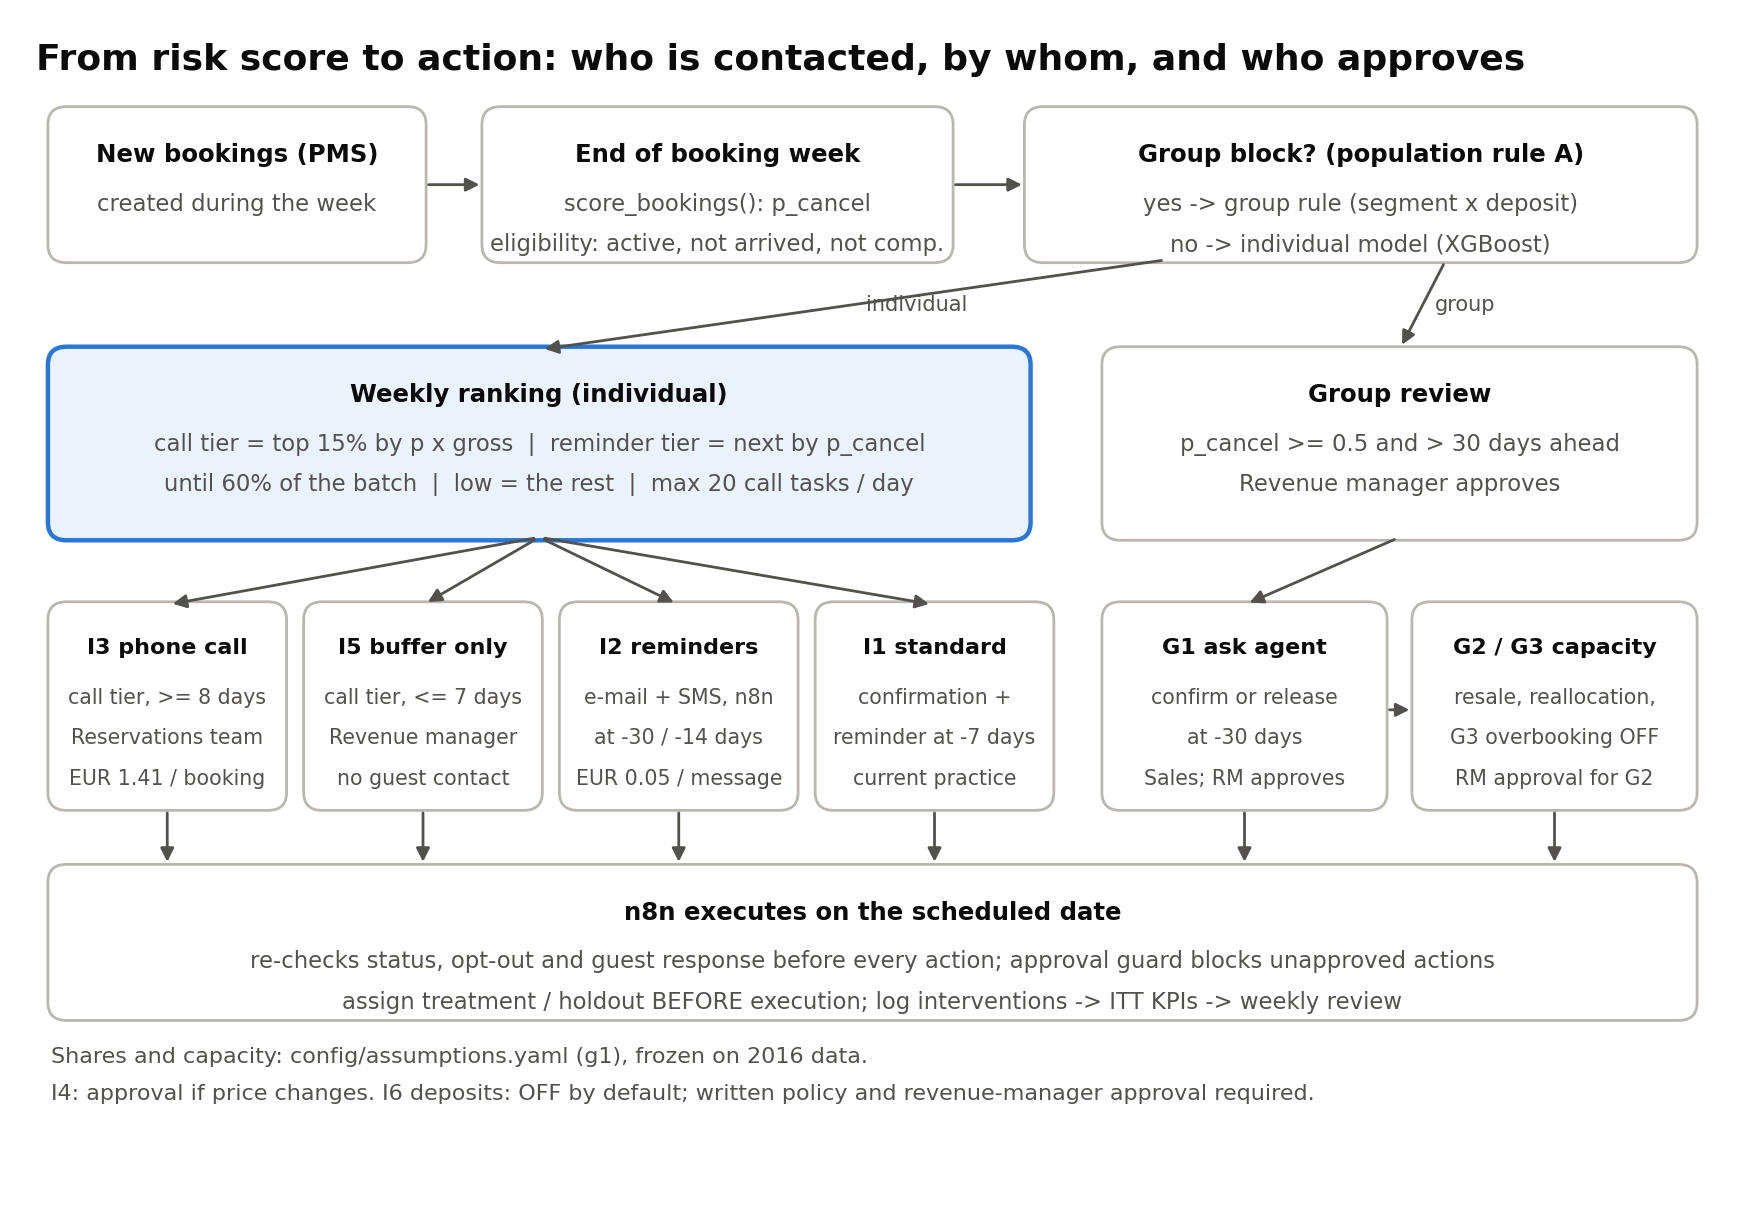

In [18]:
def box(ax, x, y, w, h, title, lines=(), accent=False, fs=8.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.12', lw=1.6 if accent else 1.0,
                                ec=ACCENT if accent else MUTED, fc='#eaf2fb' if accent else 'white'))
    ax.text(x + w / 2, y + h - 0.22, title, ha='center', va='top', fontsize=fs + 0.6, fontweight='bold', color=INK)
    for i, l in enumerate(lines):
        ax.text(x + w / 2, y + h - 0.55 - 0.27 * i, l, ha='center', va='top', fontsize=fs, color=INK2)
def arrow(ax, x1, y1, x2, y2, label=None):
    ax.annotate('', (x2, y2), (x1, y1), arrowprops=dict(arrowstyle='-|>', color=INK2, lw=1.0, shrinkA=2, shrinkB=2))
    if label:
        ax.text((x1 + x2) / 2 + 0.08, (y1 + y2) / 2, label, fontsize=7.5, color=INK2, va='center')

fig, ax = plt.subplots(figsize=(11, 7.6)); ax.set_xlim(0, 11); ax.set_ylim(0, 7.8); ax.axis('off')
ax.text(0.1, 7.65, 'From risk score to action: who is contacted, by whom, and who approves', fontsize=13, fontweight='bold', color=INK, va='top')
box(ax, 0.2, 6.2, 2.4, 1.0, 'New bookings (PMS)', ['created during the week'])
box(ax, 3.0, 6.2, 3.0, 1.0, 'End of booking week', ['score_bookings(): p_cancel', 'eligibility: active, not arrived, not comp.'])
box(ax, 6.5, 6.2, 4.3, 1.0, 'Group block? (population rule A)', ['yes -> group rule (segment x deposit)', 'no -> individual model (XGBoost)'])
arrow(ax, 2.6, 6.7, 3.0, 6.7); arrow(ax, 6.0, 6.7, 6.5, 6.7)
box(ax, 0.2, 4.35, 6.3, 1.25, 'Weekly ranking (individual)', [f"call tier = top {POLICY['high_share']:.0%} by {POLICY['high_rank'].replace('_', ' ')}  |  reminder tier = next by p_cancel",
    f"until {POLICY['contact_share']:.0%} of the batch  |  low = the rest  |  max {call_cap} call tasks / day"], accent=True)
box(ax, 7.0, 4.35, 3.8, 1.25, 'Group review', [f"p_cancel >= {GT['flag_threshold']} and > {GT['release_ask_days']} days ahead", 'Revenue manager approves'])
arrow(ax, 7.4, 6.2, 3.35, 5.6, 'individual'); arrow(ax, 9.2, 6.2, 8.9, 5.6, 'group')
xs = [0.2, 1.85, 3.5, 5.15]
for x, (t, ls) in zip(xs, [('I3 phone call', ['call tier, >= 8 days', 'Reservations team', f'EUR {CALL_COST:.2f} / booking']),
                           ('I5 buffer only', ['call tier, <= 7 days', 'Revenue manager', 'no guest contact']),
                           ('I2 reminders', ['e-mail + SMS, n8n', 'at -30 / -14 days', f'EUR {MSG_COST:.2f} / message']),
                           ('I1 standard', ['confirmation +', 'reminder at -7 days', 'current practice'])]):
    box(ax, x, 2.55, 1.5, 1.35, t, ls, fs=7.4)
    arrow(ax, 3.35, 4.35, x + 0.75, 3.9)
box(ax, 7.0, 2.55, 1.8, 1.35, 'G1 ask agent', ['confirm or release', f"at -{GT['release_ask_days']} days", 'Sales; RM approves'], fs=7.4)
box(ax, 9.0, 2.55, 1.8, 1.35, 'G2 / G3 capacity', ['resale, reallocation,', 'G3 overbooking OFF', 'RM approval for G2'], fs=7.4)
arrow(ax, 8.9, 4.35, 7.9, 3.9); arrow(ax, 8.8, 3.2, 9.0, 3.2)
box(ax, 0.2, 1.15, 10.6, 1.0, 'n8n executes on the scheduled date', ['re-checks status, opt-out and guest response before every action; approval guard blocks unapproved actions',
    'assign treatment / holdout BEFORE execution; log interventions -> ITT KPIs -> weekly review'])
for x in [0.95, 2.6, 4.25, 5.9, 7.9, 9.9]:
    arrow(ax, x, 2.55, x, 2.15)
ax.text(0.2, 0.85, 'Shares and capacity: config/assumptions.yaml (g1), frozen on 2016 data.', fontsize=8, color=INK2)
ax.text(0.2, 0.6, 'I4: approval if price changes. I6 deposits: OFF by default; written policy and revenue-manager approval required.', fontsize=8, color=INK2)
save(fig, 'fig_g1_decision_workflow.png')

In [19]:
OUT.mkdir(parents=True, exist_ok=True)
GRID16.to_csv(OUT / 'policy_grid_2016.csv', index=False)
SCEN.to_csv(OUT / 'scenarios_2017.csv')
SENS.to_csv(OUT / 'sensitivity_s4.csv', index=False)
BREAK.to_csv(OUT / 'break_even_uplift.csv')
CURVE.rename_axis('uplift_multiplier').to_csv(OUT / 'uplift_curve.csv')
BC.to_csv(OUT / 'business_case.csv')
BC_SENS.to_csv(OUT / 'business_case_sensitivity.csv', index=False)
PILOT.to_csv(OUT / 'pilot_power.csv')
ML_VS_RULE.to_csv(OUT / 'model_vs_rule_at_g1_policy.csv')
OB_GRID16.to_csv(OUT / 'overbooking_grid_2016.csv', index=False)
OB17.to_csv(OUT / 'overbooking_2017.csv')
pd.Series(SELLOUT).to_csv(OUT / 'sellout_check.csv', header=['value'])
pd.Series(GROUP).to_csv(OUT / 'group_track_estimate.csv', header=['value'])
RULES.to_csv(OUT / 'decision_rules_g1.csv', index=False)
plan.to_csv(OUT / 'action_queue_g1_2017.csv', index=False)
ACTION_SCHEDULE.to_csv(OUT / 'action_schedule_g1_2017.csv', index=False)
EVALUATION.to_csv(OUT / 'retrospective_evaluation_2017.csv', index=False)
policy_file = {'policy': POLICY, 'call_capacity_per_day': call_cap, 'decision_time': MANIFEST_F['config']['decision_time'],
               'tiering': 'call tier = first floor(high_share x batch) by high_rank; reminder tier = next by p_cancel up to floor(contact_share x batch)',
               'rules': {'I3_min_days': 8, 'I2_min_days': 8, 'I2_milestones_days': [30, 14], 'I2_max_messages': 2, 'I1_reminder_days': 7},
               'group_track': {'flag_threshold': GT['flag_threshold'], 'release_ask_days': GT['release_ask_days']},
               'chosen_on': '2016 weekly rolling predictions; only outcomes known by 2016-12-31', 'rolling_selection': ROLLING_AUDIT, 'stage_f_run': MANIFEST_F['run_id'],
               'assumptions': {k: BASE[k] for k in BASE},
               'schema_version': 2, 'call_schedule': G['call_schedule'],
               'overbooking': {'enabled': False, 'reason': G['overbooking']['disabled_reason']},
               'roi_definition': G['roi_definition'],
               'evaluation_file': 'retrospective_evaluation_2017.csv',
               'schedule_file': 'action_schedule_g1_2017.csv',
               'execution_checks': ['status', 'arrival window', 'consent', 'open actions', 'guest response', 'daily capacity']}
(OUT / 'g1_policy.json').write_text(json.dumps(policy_file, indent=2), encoding='utf-8')
KEY = {'queue_2017_bookings': len(Q17), 'weeks_2017': W17, 'annualisation_factor': G['weeks_per_year'] / W17,
       'chosen_policy': POLICY, 'S4_net_per_year': BC.loc['S4 G1 policy', 'annual_net_benefit_eur'],
       'S4_roi_3y': BC.loc['S4 G1 policy', f'roi_{Y}y'], 'S4_payback_months': BC.loc['S4 G1 policy', 'payback_months'],
       'one_off': one_off, 'running': running, 'volume_factor_2016': VOL_FACTOR,
       'queue_kpi_top20': {'precision_2016': prec16, 'lift_2016': lift16, 'precision_2017': prec17, 'lift_2017': lift17},
       'calls_per_day_2017': {'mean_on_scheduled_days': calls_day.mean(), 'max': calls_day.max()}, 'call_capacity_check': CALL_CAPACITY_CHECK,
       'overbooking': {'enabled': False, 'analysis_only': True, 'policy': OB_POLICY, 'net_2017': OB17.iloc[0]['net_eur'], 'net_per_year': OB17.iloc[0]['net_eur_per_year'], 'walks_2017': OB17.iloc[0]['walks']}}
(OUT / 'key_numbers.json').write_text(json.dumps(KEY, indent=2, default=float), encoding='utf-8')
print('Wrote', sorted(p.name for p in OUT.glob('*')), 'and figures', sorted(p.name for p in FIG.glob('*.png')))
from g1_reporting import update_documents
update_documents(ROOT, KEY, BC, PILOT, BREAK, plan, ACTION_SCHEDULE, G)


Wrote ['action_queue_g1_2017.csv', 'action_schedule_g1_2017.csv', 'break_even_uplift.csv', 'business_case.csv', 'business_case_sensitivity.csv', 'decision_rules_g1.csv', 'figures', 'g1_policy.json', 'group_track_estimate.csv', 'key_numbers.json', 'model_vs_rule_at_g1_policy.csv', 'overbooking_2017.csv', 'overbooking_grid_2016.csv', 'pilot_power.csv', 'policy_grid_2016.csv', 'retrospective_evaluation_2017.csv', 'rolling_selection', 'scenarios_2017.csv', 'sellout_check.csv', 'sensitivity_s4.csv', 'uplift_curve.csv'] and figures ['fig_g1_decision_workflow.png', 'fig_g1_payback.png', 'fig_g1_policy_selection_2016.png', 'fig_g1_scenarios_2017.png', 'fig_g1_sensitivity_tornado.png', 'fig_g1_uplift_curve.png']
